# Data analysis for ingest pipeline

Validate that TasteMender's imported audio-feature data is complete, internally consistent, and faithful to the original AcousticBrainz source data.

This work should identify any issues introduced during ingestion, transformation, normalization, or storage, and establish whether each feature provides enough useful variation to support recommendation ranking.

Links:
- https://acousticbrainz.org/datasets/accuracy

In [1]:
import os, uuid, sys, random
import django
import numpy as np
import numpy.typing as npt
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from IPython.display import Markdown, display

# Enable access to Django project inside current notebook
PROJECT_PATH = os.path.abspath(os.path.join("..", ".."))
sys.path.append(PROJECT_PATH)
os.environ["DJANGO_SETTINGS_MODULE"] = "music_recommendation.settings"
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"
django.setup()

# Ensure the latest version of analysis_helpers is imported
%load_ext autoreload
%autoreload 1
%aimport ingest.analysis.analysis_helpers

from django.conf import settings
from recommend_api.models import GenreDortmund, GenreRosamerica, Track, Artist, Album
import ingest.analysis.analysis_helpers as analysis_helpers
from ingest.analysis.analysis_helpers import export_stats
from ingest.core.cli_helpers import fg, bg, style

### Genre distribution by classifier

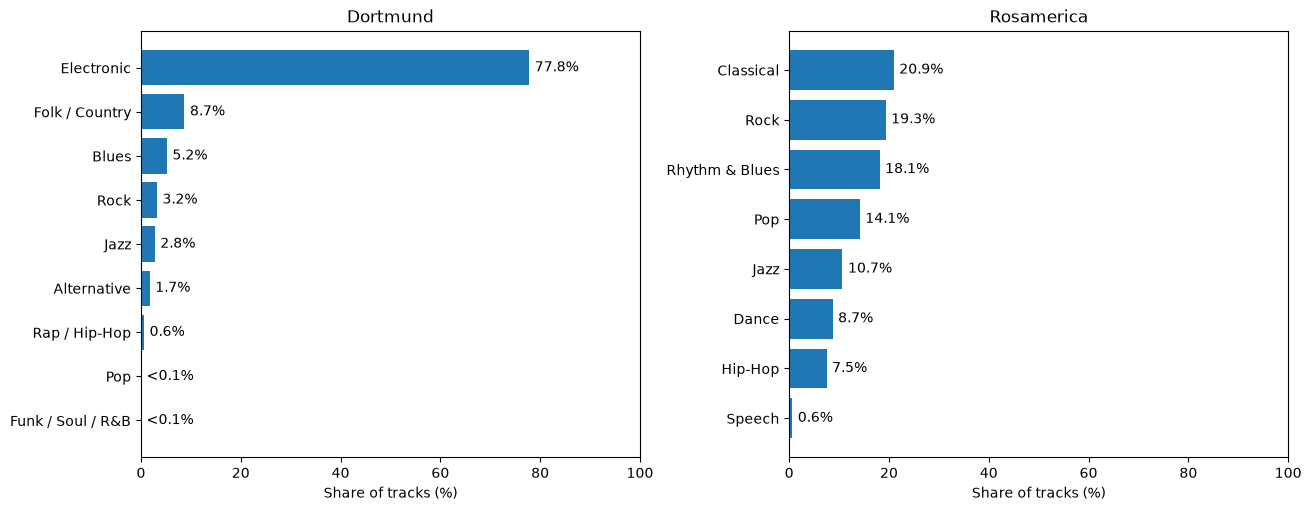

In [2]:
feature_store = np.load(settings.BASE_DIR / settings.FEATURE_MATRIX_FILENAME, allow_pickle=True, mmap_mode="r")

genre_display_names = {
    "folkcountry": "Folk / Country",
    "funksoulrnb": "Funk / Soul / R&B",
    "raphiphop": "Rap / Hip-Hop",
    "cla": "Classical",
    "dan": "Dance",
    "hip": "Hip-Hop",
    "jaz": "Jazz",
    "rhy": "Rhythm & Blues",
    "roc": "Rock",
    "spe": "Speech",
}
genre_classifiers = (
    ("Dortmund", "genre_dortmund", GenreDortmund),
    ("Rosamerica", "genre_rosamerica", GenreRosamerica),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, layout="constrained")
for axis, (classifier, feature_key, genre_model) in zip(axes, genre_classifiers):
    shares = pd.Series(feature_store[feature_key]).value_counts(normalize=True) * 100
    labels_by_code = dict(genre_model.objects.values_list("code", "label"))
    labels = [labels_by_code[code] for code in shares.index]
    names = [genre_display_names.get(label, label.title()) for label in labels]
    bars = axis.barh(names, shares)
    axis.invert_yaxis()
    share_labels = [f"{share:.1f}%" if share >= 0.1 else "<0.1%" for share in shares]
    axis.bar_label(bars, labels=share_labels, padding=4)
    axis.set(title=classifier, xlabel="Share of tracks (%)", xlim=(0, 100))

plt.show()

The Dortmund classification designates a whopping 77.8% as being electronic music while Rosamerica splits up genres more evenly. The official AcousticBrainz [accuracy metrics](https://acousticbrainz.org/datasets/accuracy) put Dortmund at 60.25% and Rosamerica at 87.56%.

We can safely conclude that the Rosamerica classification is the best choice for determining musical genre in TasteMender due to its higher accuracy.

### Feature Distribution - Normalized vs Raw
Audio features go through 3 different representations before they can be used by the recommender logic. They are:
- **raw** - the original audio features that are extracted from AcousticBrainz JSON dataset
- **standardized** - each feature is transformed to have mean 0 and standard deviation 1 using `StandardScaler`
- **normalized** - the complete feature vector for each track is divided by its Euclidean norm for cosine similarity

It's currently unclear if and how changing representations affects the recommendation logic. Since this is the core of the project, it worthwhile to make a deep dive into this aspect as well as the logic in general. We'll begin by comparing the representations for all of the audio features.

Questions that should be answered:
- How are features distributed in general?
- Does standardization and normalization change the shape of the distribution?

Note: The DB ingestion pipeline skips submissions that are missing metadata. For example Pharrell Williams' "Happy" has 326 submissions but only 320 have valid metadata. Keep this discrepancy in mind as the "submissions" count in the `Track` table can be lower than number of records in the original dataset.

In [3]:
# Hardcode lists of MBIDs for analysis and get their aggregate stats
danceable_mbids = [
    "d2bab0db-b63b-45b6-8f6c-5a566620c522",  # Mambo No. 5 (A Little Bit of...) - Lou Bega
    "c7a0fed2-988b-43d2-b7ff-4055fcad868f",  # Conga - Miami Sound Machine
    "0d8df525-cc5a-4ee4-a303-e4df9ca0a685",  # Freestyler - Bomfunk MC's
    "a502f559-f70c-4e0d-a5e5-e0cc319d0bd7",  # Dancing Queen - ABBA
    "60fa767a-d85d-4991-82bc-4294e0b11ae7",  # One More Time - Daft Punk
    "24cbf6b7-bcc9-42d3-aa61-76e637bfde8c",  # Crimson and Clover - Tommy James & The Shondells
    "8121ce09-135d-477d-aafb-0404f1f15b78",  # Blue in Green - Miles Davis
    "141b174e-ee58-4447-990a-6806180b455b",  # The Sound of Silence - Simon & Garfunkel
    "d7bb88a7-d9ca-4481-9e79-5ae17c0daefb",  # Adagio for Strings - Samuel Barber
    "acc8f927-65e9-4662-8665-8127efe76e6a",  # Foil - Autechre
]
aggressive_mbids = [
    "62c2e20a-559e-422f-a44c-9afa7882f0c4",  # Enter Sandman - Metallica
    "c7c25302-69ab-4a9d-b967-23cbc6793854",  # Hells Bells - AC/DC
    "06748144-5e3a-4ce3-ae4f-3d15768089af",  # Hearts on Fire - HammerFall
    "03cf6e1b-d986-402f-b67e-9fbe2ebc906d",  # Burning Times - Iced Earth
    "5053c294-90fe-47e9-9e21-1a4c4538c20f",  # Bad Medicine - Bon Jovi
    "37295d29-229a-4609-bb53-0a72e5e0a467",  # 2 Minutes to Midnight - Iron Maiden
    "71209300-34e5-491d-81ad-76237d167604",  # Ace of Spades - Motörhead
    "9190aac9-cbb1-4f26-8b4c-169e08d7897a",  # Bed of Roses - Bon Jovi
    "b1a9c0e9-d987-4042-ae91-78d6a3267d69",  # Bohemian Rhapsody - Queen
    "2dacc772-bff6-4347-a586-8bff3a7d7c79",  # Nothing Else Matters - Metallica
]
# For each title/artist pair, use the recording with the most stored submissions.
happy_mbids = [
    "f367ad6e-efd5-4496-aba5-21a4edcd82c6",  # Happy - Pharrell Williams
    "d4009c09-a339-4b89-bc45-d91ab649acb6",  # Don't Stop Me Now - Queen
    "2138bf67-fe08-46d3-863d-560e1b8c3043",  # Walking on Sunshine - Katrina and the Waves
    "3ad31947-ae54-4409-aeaa-8dbd16c3825f",  # Good Vibrations - The Beach Boys
    "440f60e8-0b25-4ec4-abb1-c6beec624ab0",  # Here Comes the Sun - The Beatles
    "6e33056b-2a34-4ed0-b49c-f7a8ae2c5bcc",  # Mr. Blue Sky - Electric Light Orchestra
    "2d6daa5a-19d9-4254-b149-26f162c4634f",  # Lovely Day - Bill Withers
    "25d8de5e-3662-4ffd-8dea-511a696ac3e7",  # Hurt - Johnny Cash
    "49eb0679-0a3d-4be5-9adf-973cd429b9a7",  # Mad World - Gary Jules
    "bc10b379-413a-49d9-b6a5-36771762c4d3",  # Tears in Heaven - Eric Clapton
]
sad_mbids = [
    "25d8de5e-3662-4ffd-8dea-511a696ac3e7",  # Hurt - Johnny Cash
    "b9109195-0449-4900-9399-339882b38c29",  # Everybody Hurts - R.E.M.
    "028efe7f-cdfb-4135-846f-848f2fff15b1",  # Someone Like You - Adele
    "31fb9fce-395c-4556-83c7-f0a2abf12b3a",  # Nothing Compares 2 U - Sinéad O'Connor
    "bc10b379-413a-49d9-b6a5-36771762c4d3",  # Tears in Heaven - Eric Clapton
    "49eb0679-0a3d-4be5-9adf-973cd429b9a7",  # Mad World - Gary Jules
    "a478f801-521b-40e7-8bb4-5faeffb1f3e4",  # The Scientist - Coldplay
    "760828c4-c062-4667-94c6-0d358c1c768c",  # River - Joni Mitchell
    "f367ad6e-efd5-4496-aba5-21a4edcd82c6",  # Happy - Pharrell Williams
    "d4009c09-a339-4b89-bc45-d91ab649acb6",  # Don't Stop Me Now - Queen
    "3ad31947-ae54-4409-aeaa-8dbd16c3825f",  # Good Vibrations - The Beach Boys
]
relaxed_mbids = [
    "8121ce09-135d-477d-aafb-0404f1f15b78",  # Blue in Green - Miles Davis
    "306442b9-13d3-4e7c-b2c9-dcbe12ad0b22",  # An Ending (Ascent) - Brian Eno
    "6e686d11-0191-4021-9bb7-a46535709ca4",  # Watermark - Enya
    "b79e4c16-c6ed-49b8-b867-1a89ebe6ddd1",  # Clair De Lune - Claude Debussy
    "a38c28ee-4430-4429-b3e7-e7920895b2d2",  # Come Away With Me - Norah Jones
    "548bfe47-8d1c-4a4d-8a0f-2f9a4ee6af5b",  # Better Together - Jack Johnson
    "864c7424-c9ab-481e-a9c0-ad986e646c67",  # La Femme d'argent - Air
    "120bdf8e-c760-4aaf-8e34-ddd1ab3be504",  # Territorial Pissings - Nirvana
    "3dabfc40-33b4-4dba-8d94-79e77c4d1448",  # Firestarter - The Prodigy
    "1675aafe-397d-41fc-b7f6-fde5681f56c4",  # Raining Blood - Slayer
]
party_mbids = [
    "7c5b6609-0e04-4ea4-a871-513301db8c9a",  # Party Rock Anthem - LMFAO
    "7d9d4262-656c-4e93-ad42-0e0ccfbf0635",  # Celebration - Kool & The Gang
    "4f595ab5-18bb-4007-b17d-066a0e704234",  # Yeah! - Usher
    "4c0566be-d3d9-42b2-964d-cf349972123b",  # Don't Stop the Music - Rihanna
    "ef96f0f7-b26b-421e-a0e3-b9fdb45cd500",  # Get the Party Started - P!nk
    "0810268f-2e52-4f89-86be-42762ea3f6d4",  # Just Dance - Lady Gaga
    "abcb30ab-58a7-4f63-9699-952b9b422fc2",  # I Gotta Feeling - The Black Eyed Peas
    "b75c56c6-cbfc-4d1a-83fd-b2e3f97194cf",  # On the Nature of Daylight - Max Richter
    "dbdd9b68-8971-4ff8-abec-40a00119dd82",  # Strange Fruit - Billie Holiday
    "9c9ee25e-f321-4d35-b126-2316c488beae",  # Gymnopédie no. 1 - Erik Satie
]
acoustic_examples = {
    "b4184747-0157-41be-ae44-e3a6a0c13272": "Studio",  # Come as You Are - Nirvana
    "9738401c-5720-4569-8f56-9780b8b0ab2e": "Unplugged",  # Come as You Are - Nirvana
    "70595637-9310-45f2-a266-58f8de4874a7": "Studio",  # Creep - Radiohead
    "7cdf2e8e-f52c-4008-a493-d37b41fc1004": "Acoustic version",  # Creep (acoustic) - Radiohead
    "8121ce09-135d-477d-aafb-0404f1f15b78": "Acoustic",  # Blue in Green - Miles Davis
    "dbdd9b68-8971-4ff8-abec-40a00119dd82": "Acoustic",  # Strange Fruit - Billie Holiday
    "9c9ee25e-f321-4d35-b126-2316c488beae": "Acoustic",  # Gymnopédie no. 1 - Erik Satie
    "17416564-fb6e-471c-a4ad-0bfc45292cd9": "Acoustic", # Blackbird - Beatles
    "60fa767a-d85d-4991-82bc-4294e0b11ae7": "Electronic",  # One More Time - Daft Punk
    "3dabfc40-33b4-4dba-8d94-79e77c4d1448": "Electronic",  # Firestarter - The Prodigy
    "864c7424-c9ab-481e-a9c0-ad986e646c67": "Hybrid",  # La Femme d’argent - Air
    "a7ed3365-affa-4331-8bd9-1ececaf9ae77": "Hybrid",  # The Rip - Portishead
}
acoustic_mbids = list(acoustic_examples)
electronic_examples = {
    "65bf94b8-6d5d-4254-aa5f-a939b1794303": "Electronic",  # Hyperballad - Björk
    "896b2ffc-5358-4942-b2df-b37d7148ebef": "String quartet version",  # Hyperballad - Björk
    "28b9dce4-05f9-4fe0-8eb1-55c824310f1b": "Electronic",  # Take On Me - a-ha
    "e3982390-ef01-4ebb-a84b-2a1fdbbd9f96": "Unplugged",  # Take On Me - a-ha
    "c3425799-284e-454a-a006-873c953f1cad": "Electronic",  # The Robots - Kraftwerk
    "60fa767a-d85d-4991-82bc-4294e0b11ae7": "Electronic",  # One More Time - Daft Punk
    "550a5e60-445c-446e-a3d0-390c1ca5dfc7": "Electronic", # Popcorn - Hot Butter
    "9c9ee25e-f321-4d35-b126-2316c488beae": "Acoustic",  # Gymnopédie no. 1 - Erik Satie
    "b4184747-0157-41be-ae44-e3a6a0c13272": "Amplified rock",  # Come as You Are - Nirvana
    "864c7424-c9ab-481e-a9c0-ad986e646c67": "Hybrid",  # La Femme d’argent - Air
    "a7ed3365-affa-4331-8bd9-1ececaf9ae77": "Hybrid",  # The Rip - Portishead
}
electronic_mbids = list(electronic_examples)
instrumental_examples = {
    "3dabfc40-33b4-4dba-8d94-79e77c4d1448": "Vocal version",  # Firestarter - The Prodigy
    "82e46ba4-b677-480b-baca-7fe8270e34bf": "Instrumental version",  # Firestarter - The Prodigy
    "8121ce09-135d-477d-aafb-0404f1f15b78": "Instrumental",  # Blue in Green - Miles Davis
    "9c9ee25e-f321-4d35-b126-2316c488beae": "Instrumental",  # Gymnopédie no. 1 - Erik Satie
    "028efe7f-cdfb-4135-846f-848f2fff15b1": "Sung vocals",  # Someone Like You - Adele
    "dbdd9b68-8971-4ff8-abec-40a00119dd82": "Sung vocals",  # Strange Fruit - Billie Holiday
    "73b01cea-2dad-4fc2-9e61-02a31477c1b1": "Wordless vocals",  # The Great Gig in the Sky - Pink Floyd
    "6a89527f-8994-412b-ac5b-36e098d0bef8": "Wordless vocals",  # Boadicea - Enya
    "ea8095ef-700b-4a06-9f40-9b22120c3d32": "Spoken samples",  # Frontier Psychiatrist - The Avalanches
    "f1a6a40f-78f5-4918-968d-f64363bae94c": "Processed vocals",  # Harder, Better, Faster, Stronger - Daft Punk
}
instrumental_mbids = list(instrumental_examples)
tonal_examples = {
    "0cdc9b5b-b16b-4ff1-9f16-5b4ba76f1c17": "tonal",  # Let It Be - The Beatles
    "e54fc23c-edd0-422c-aa21-ffd111b88af3": "tonal",  # Twinkle, Twinkle Little Star - Traditional, performed by Jewel
    "b4459c7c-5b96-41f6-b792-21de5a213cb6": "tonal",  # Für Elise - Ludwig van Beethoven
    "35ef1ecc-c02a-474f-abbf-75ac7504eab5": "tonal",  # Billie Jean - Michael Jackson (Thriller)
    "b79e4c16-c6ed-49b8-b867-1a89ebe6ddd1": "tonal",  # Clair de Lune - Claude Debussy
    "85c624da-223a-4076-bb79-25724ac91642": "tonal",  # Devil Trigger - Casey Edwards
    "0e2be6be-8cef-4bbb-8a9e-99aaf0a890d2": "atonal",  # Suite for Piano, Op. 25 - Arnold Schoenberg
    "41e0be59-e3e4-4114-815d-9c4be183d1fe": "atonal",  # Ionisation - Edgard Varèse
    "f85db1e5-bc16-4358-ad07-5cfabbfb9716": "atonal",  # Three Pieces for Piano, Op. 11: III. Bewegt - Arnold Schoenberg
    "a5ccb539-6aae-40ad-8a54-809cd6bceba7": "atonal",  # Threnody for the Victims of Hiroshima - Krzysztof Penderecki
    "c6c57410-8567-4254-8b17-2682879c009e": "atonal",  # The Rite of Spring: The Augurs of Spring - Igor Stravinsky
}
tonal_mbids = list(tonal_examples)
brightness_examples = {
    "28b9dce4-05f9-4fe0-8eb1-55c824310f1b": "Bright",  # Take On Me - a-ha (studio)
    "e3982390-ef01-4ebb-a84b-2a1fdbbd9f96": "Softer than studio",  # Take On Me - a-ha (unplugged)
    "2138bf67-fe08-46d3-863d-560e1b8c3043": "Bright",  # Walking on Sunshine - Katrina and the Waves
    "550a5e60-445c-446e-a3d0-390c1ca5dfc7": "Bright",  # Popcorn - Hot Butter
    "17416564-fb6e-471c-a4ad-0bfc45292cd9": "Bright",  # Blackbird - The Beatles
    "120bdf8e-c760-4aaf-8e34-ddd1ab3be504": "Bright",  # Territorial Pissings - Nirvana
    "8121ce09-135d-477d-aafb-0404f1f15b78": "Dark",  # Blue in Green - Miles Davis
    "b75c56c6-cbfc-4d1a-83fd-b2e3f97194cf": "Dark",  # On the Nature of Daylight - Max Richter
    "6a89527f-8994-412b-ac5b-36e098d0bef8": "Dark",  # Boadicea - Enya
    "49eb0679-0a3d-4be5-9adf-973cd429b9a7": "Dark",  # Mad World - Gary Jules
}
brightness_mbids = list(brightness_examples)
# Deduplicate mbids while preserving order for consistency between runs
target_mbids = list(dict.fromkeys(
    danceable_mbids + aggressive_mbids + happy_mbids + sad_mbids + relaxed_mbids
    + party_mbids + acoustic_mbids + electronic_mbids + instrumental_mbids + tonal_mbids + brightness_mbids
))

feature_stats = analysis_helpers.aggregate_stats(target_mbids, use_sample=False, num_parts=None)

Trying to get submissions from cache.


In [4]:
# Show names of features and the shapes of the raw and normalized feature matrices.
features_raw = feature_store["feature_matrix_raw"]
features_norm = feature_store["feature_matrix"]
feature_names = feature_store["feature_names"]

display(Markdown("**Feature matrix overview**"))
print("Audio features: \n", feature_names)
print("Shape of raw feature matrix: ", features_raw.shape)
print("Shape of normalized feature matrix:", features_norm.shape)

**Feature matrix overview**

Audio features: 
 ['danceability' 'aggressiveness' 'happiness' 'sadness' 'relaxedness'
 'partyness' 'acousticness' 'electronicness' 'instrumentalness' 'tonality'
 'brightness' 'moods_mirex_1' 'moods_mirex_2' 'moods_mirex_3'
 'moods_mirex_4' 'moods_mirex_5']
Shape of raw feature matrix:  (5261105, 16)
Shape of normalized feature matrix: (5261105, 16)


In [5]:
# Generate standardized matrix from raw features
scaler = StandardScaler(with_mean=True, with_std=True).fit(features_raw)
features_scaled = scaler.transform(features_raw).astype(np.float32)

# Re-generate the normalized matrix so we can compare against the one saved in the store
temp_features_norm = features_scaled / (
    np.linalg.norm(features_scaled, axis=1, keepdims=True) + 1e-8
)

# Check normalized matrix in store is correct
assert np.array_equal(temp_features_norm, features_norm) is True

feature_df = pd.DataFrame(features_raw, columns=feature_names)

display(Markdown("**Values in the raw feature matrix**"))
display(feature_df.head())

**Values in the raw feature matrix**

,danceability,aggressiveness,happiness,sadness,relaxedness,partyness,acousticness,electronicness,instrumentalness,tonality,brightness,moods_mirex_1,moods_mirex_2,moods_mirex_3,moods_mirex_4,moods_mirex_5
0,0.365151,7.162451e-02,0.385867,0.486810,0.529347,0.177599,2.932893e-01,0.276273,0.059651,0.183365,0.060576,0.101120,0.141926,0.313746,0.066944,0.376264
1,0.709609,2.164863e-01,0.053050,0.339952,0.947380,0.544873,3.670051e-01,0.875206,1.000000,0.000002,0.084642,0.072096,0.045744,0.247723,0.034688,0.599749
2,0.262318,5.051706e-02,0.277146,0.952537,0.989301,0.008651,9.010097e-01,0.108439,0.038802,0.972661,0.693319,0.091009,0.336622,0.388044,0.096563,0.087762
3,0.998323,8.263321e-01,0.272118,0.063539,0.037000,0.945496,4.595298e-06,0.777945,0.289999,0.311504,0.138182,0.110087,0.154394,0.071212,0.140863,0.523445
4,0.999924,3.000001e-14,0.413965,0.066315,0.808132,0.009676,6.022433e-07,0.681410,0.575784,0.777671,0.381640,0.330578,0.056705,0.083606,0.055130,0.473982


In [6]:
basic_stats = feature_df.agg(["mean", "std", "min", "max",]).T

with pd.option_context('display.float_format', lambda x: f'{x:,.4f}'):
    display(Markdown("**Basic stats for raw feature matrix**"))
    display(basic_stats)

**Basic stats for raw feature matrix**

,mean,std,min,max
danceability,0.4331,0.3979,0.0000,1.0000
aggressiveness,0.2334,0.3247,0.0000,1.0000
happiness,0.3738,0.2912,0.0000,1.0000
sadness,0.4245,0.2576,0.0005,0.9972
relaxedness,0.6347,0.3269,0.0003,1.0000
partyness,0.3316,0.3246,0.0000,1.0000
acousticness,0.3956,0.3866,0.0000,1.0000
electronicness,0.5201,0.3272,0.0000,1.0000
instrumentalness,0.4974,0.4018,0.0000,1.0000
tonality,0.4727,0.3778,0.0000,1.0000


In [7]:
percentiles = (
    feature_df.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
    .rename(columns=lambda x: f"{x:.0%}")
)

display(Markdown(
    "**Percentiles for the raw feature matrix**\n\n"
    "Each column gives the score at that percentile across tracks. "
    "Values are rounded to four decimal places, so `0.0000` and `1.0000` can represent scores close to the endpoints."
))
with pd.option_context('display.float_format', lambda x: f'{x:,.4f}'):
    display(percentiles)

**Percentiles for the raw feature matrix**

Each column gives the score at that percentile across tracks. Values are rounded to four decimal places, so `0.0000` and `1.0000` can represent scores close to the endpoints.

,1%,5%,25%,50%,75%,95%,99%
danceability,0.0000,0.0000,0.0387,0.3050,0.8976,1.0000,1.0000
aggressiveness,0.0000,0.0000,0.0085,0.0616,0.3352,0.9883,1.0000
happiness,0.0000,0.0129,0.1189,0.3107,0.5934,0.9266,0.9994
sadness,0.0174,0.0569,0.2144,0.3803,0.6278,0.8826,0.9467
relaxedness,0.0105,0.0398,0.3518,0.7890,0.9125,0.9925,1.0000
partyness,0.0000,0.0000,0.0278,0.2161,0.6184,0.9195,0.9797
acousticness,0.0000,0.0000,0.0257,0.2298,0.8247,0.9914,0.9996
electronicness,0.0184,0.0503,0.2100,0.5068,0.8481,0.9794,0.9945
instrumentalness,0.0002,0.0024,0.0634,0.4765,0.9496,1.0000,1.0000
tonality,0.0000,0.0000,0.0732,0.4459,0.8748,0.9930,0.9994


#### Danceability

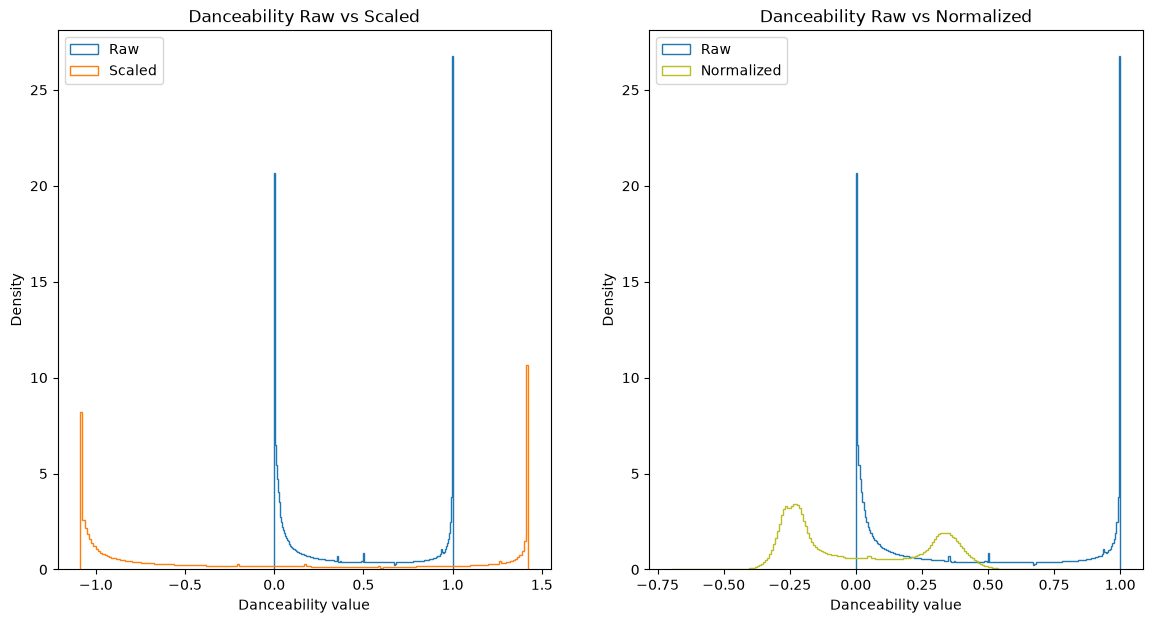

In [8]:
# Compare danceability histogram between raw, scaled and normalized matrices
danc_raw = features_raw[:, feature_names == "danceability"].flatten()
danc_scaled = features_scaled[:, feature_names == "danceability"].flatten()
danc_normalized = features_norm[:, feature_names == "danceability"].flatten()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    danc_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
)
axes[0].hist(
    danc_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Danceability Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    danc_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
)
axes[1].hist(
    danc_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Danceability Raw vs Normalized")
axes[1].legend()

for axis in axes:
    axis.set_xlabel("Danceability value")
    axis.set_ylabel("Density")
plt.show()

In [9]:
danc_stats_df = pd.DataFrame({
    "min": [danc_raw.min(), danc_scaled.min(), danc_normalized.min()],
    "max": [danc_raw.max(), danc_scaled.max(), danc_normalized.max()],
    "mean": [danc_raw.mean(), danc_scaled.mean(), danc_normalized.mean()],
    "std": [danc_raw.std(), danc_scaled.std(), danc_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.4f}'):
    display(Markdown("**Basic stats for danceability**"))
    display(danc_stats_df)

**Basic stats for danceability**

,min,max,mean,std
raw,0.0000,1.0000,0.4331,0.3979
scaled,-1.0886,1.4246,0.0000,1.0000
normalized,-0.6960,0.8091,0.0060,0.2631


In [10]:
near_zero = (danc_raw < 0.01).mean() * 100
nearish_zero = (danc_raw < 0.1).mean() * 100
near_one = (danc_raw > 0.99).mean() * 100
nearish_one = (danc_raw > 0.9).mean() * 100
uncertain = ((danc_raw > 0.4) & (danc_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.01: {fg.GREEN}{near_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.99: {fg.GREEN}{near_one:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Uncertain predictions: {fg.MAGENTA}{uncertain:.2f}%{fg.RESET}")

Below 0.01: 13.58%
Below 0.10: 35.39%
Above 0.99: 15.26%
Above 0.90: 24.86%
Uncertain predictions: 8.14%


In [11]:
# Check the danceability of known tracks
danceable_data = []

for mbid in danceable_mbids:
    bytes = np.frombuffer(uuid.UUID(mbid).bytes, dtype="V16", count=1)[0]
    index = np.where(feature_store["mbids"] == bytes)[0][0]

    track = Track.objects.filter(musicbrainz_recordingid=mbid).prefetch_related("artists").first()
    if not track:
        continue

    artists = ", ".join(artist.name for artist in track.artists.all())

    danceable_data.append({
        "title": track.title, "artists": artists,
        "raw": danc_raw[index], "scaled": danc_scaled[index], "norm": danc_normalized[index],
        # "mbid": mbid
    })

danc_df = pd.DataFrame(danceable_data)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}The merged danceability values for known tracks \
- based on feature matrix contents{style.RESET_ALL}")
with pd.option_context('display.float_format', lambda x: f'{x:,.5f}'):
    display(danc_df)

The merged danceability values for known tracks - based on feature matrix contents


,title,artists,raw,scaled,norm
0,Mambo No. 5 (A Little Bit of...),Lou Bega,0.99959,1.42361,0.37997
1,Conga,Miami Sound Machine,0.88379,1.13257,0.28896
2,Freestyler,Bomfunk MC's,0.99735,1.41799,0.37571
3,Dancing Queen,ABBA,0.93197,1.25366,0.30231
4,One More Time,Daft Punk,0.99524,1.41268,0.44150
5,Crimson and Clover,Tommy James & The Shondells,0.16573,-0.67209,-0.27217
6,Blue in Green,Miles Davis,0.35281,-0.20192,-0.06269
7,The Sound of Silence,Simon & Garfunkel,0.09486,-0.85020,-0.26683
8,Adagio for Strings,Samuel Barber,0.03915,-0.99021,-0.28348
9,Foil,Autechre,0.62884,0.49183,0.16947


**How to read the submission tables**

The feature matrix stores one merged score per feature for each recording. The tables below summarize the individual AcousticBrainz classifier predictions for that recording.

`total_pred` counts all valid predictions for the feature, including ties. A prediction counts toward a category only when that category has the higher score. `NaN` in a summary statistic means the group had fewer than two predictions.

In [12]:
df = export_stats(feature_stats, feature="danceability", target_mbids=danceable_mbids)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}Danceability stats based on duplicate submissions found \
in the original dataset{style.RESET_ALL}")

print(f"{style.BRIGHT}Predictions{style.RESET_ALL}")
display(df[["title", "artists", "total_pred", "danceable_count", "not_danceable_count"]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}danceable{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_danceable_mean", "tagged_danceable_median", "tagged_danceable_std"
]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}not_danceable{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_not_danceable_mean", "tagged_not_danceable_median",
    "tagged_not_danceable_std"
]])

print(f"{style.BRIGHT}Statistics for all submissions (regardless of tag)")
display(df[[
    "title", "artists", "all_danceable_mean", "all_danceable_median", "all_danceable_std",
    "all_not_danceable_mean", "all_not_danceable_median", "all_not_danceable_std"
]])

Danceability stats based on duplicate submissions found in the original dataset
Predictions


,title,artists,total_pred,danceable_count,not_danceable_count
0,Mambo No. 5 (A Little Bit of...),Lou Bega,161,159,2
1,Conga,Miami Sound Machine,161,159,2
2,Freestyler,Bomfunk MC's,73,68,5
3,Dancing Queen,ABBA,594,575,19
4,One More Time,Daft Punk,438,404,33
5,Crimson and Clover,Tommy James & The Shondells,227,4,223
6,Blue in Green,Miles Davis,234,16,218
7,The Sound of Silence,Simon & Garfunkel,178,1,177
8,Adagio for Strings,Samuel Barber,73,0,73
9,Foil,Autechre,87,85,2


Statistics for submissions tagged danceable


,title,artists,tagged_danceable_mean,tagged_danceable_median,tagged_danceable_std
0,Mambo No. 5 (A Little Bit of...),Lou Bega,0.995181,0.999635,0.013026
1,Conga,Miami Sound Machine,0.894866,0.883806,0.055280
2,Freestyler,Bomfunk MC's,0.998001,0.997579,0.001189
3,Dancing Queen,ABBA,0.903713,0.933367,0.083983
4,One More Time,Daft Punk,0.975953,0.996507,0.059589
5,Crimson and Clover,Tommy James & The Shondells,0.864706,0.915852,0.176988
6,Blue in Green,Miles Davis,0.714228,0.578381,0.230412
7,The Sound of Silence,Simon & Garfunkel,NaN,NaN,NaN
8,Adagio for Strings,Samuel Barber,NaN,NaN,NaN
9,Foil,Autechre,0.631439,0.628845,0.024870


Statistics for submissions tagged not_danceable


,title,artists,tagged_not_danceable_mean,tagged_not_danceable_median,tagged_not_danceable_std
0,Mambo No. 5 (A Little Bit of...),Lou Bega,1.000000,1.000000,0.000000e+00
1,Conga,Miami Sound Machine,1.000000,1.000000,4.214710e-08
2,Freestyler,Bomfunk MC's,1.000000,1.000000,0.000000e+00
3,Dancing Queen,ABBA,0.795746,0.857639,2.013016e-01
4,One More Time,Daft Punk,0.958516,1.000000,1.130849e-01
5,Crimson and Clover,Tommy James & The Shondells,0.817467,0.835296,7.360497e-02
6,Blue in Green,Miles Davis,0.670884,0.647526,8.529505e-02
7,The Sound of Silence,Simon & Garfunkel,0.899325,0.906336,4.343295e-02
8,Adagio for Strings,Samuel Barber,0.961134,0.960847,1.226905e-03
9,Foil,Autechre,0.516384,0.516384,7.441869e-03


Statistics for all submissions (regardless of tag)


,title,artists,all_danceable_mean,all_danceable_median,all_danceable_std,all_not_danceable_mean,all_not_danceable_median,all_not_danceable_std
0,Mambo No. 5 (A Little Bit of...),Lou Bega,0.982819,0.999591,0.111327,0.017181,0.000409,0.111327
1,Conga,Miami Sound Machine,0.883750,0.883788,0.113592,0.116250,0.116212,0.113592
2,Freestyler,Bomfunk MC's,0.929645,0.997353,0.253833,0.070355,0.002647,0.253833
3,Dancing Queen,ABBA,0.881340,0.931054,0.152418,0.118660,0.068946,0.152418
4,One More Time,Daft Punk,0.904461,0.995242,0.256025,0.095539,0.004758,0.256025
5,Crimson and Clover,Tommy James & The Shondells,0.194554,0.165856,0.117597,0.805446,0.834144,0.117597
6,Blue in Green,Miles Davis,0.355449,0.353045,0.140291,0.644551,0.646955,0.140291
7,The Sound of Silence,Simon & Garfunkel,0.103194,0.094864,0.054822,0.896806,0.905136,0.054822
8,Adagio for Strings,Samuel Barber,0.038866,0.039153,0.001227,0.961134,0.960847,0.001227
9,Foil,Autechre,0.628041,0.628845,0.033186,0.371959,0.371155,0.033186


##### Conclusions
Values for the danceability feature are heavily concentrated at the extremes:
 - $~30\%$ of them being $<0.01$ or $>0.99$
 - $~60\%$ of them being $<0.10$ or $>0.90$
 
Clearly they were generated by a classifier that was determining if a song was danceable or not. The feature doesn't show _how_ danceable the song is.

This brings into question how we should view the features. So far we've assumed they were continuous variables that mapped to some sort of distribution (normal distribution). But the findings show that they're clustered at the extremes.

#### Aggressiveness

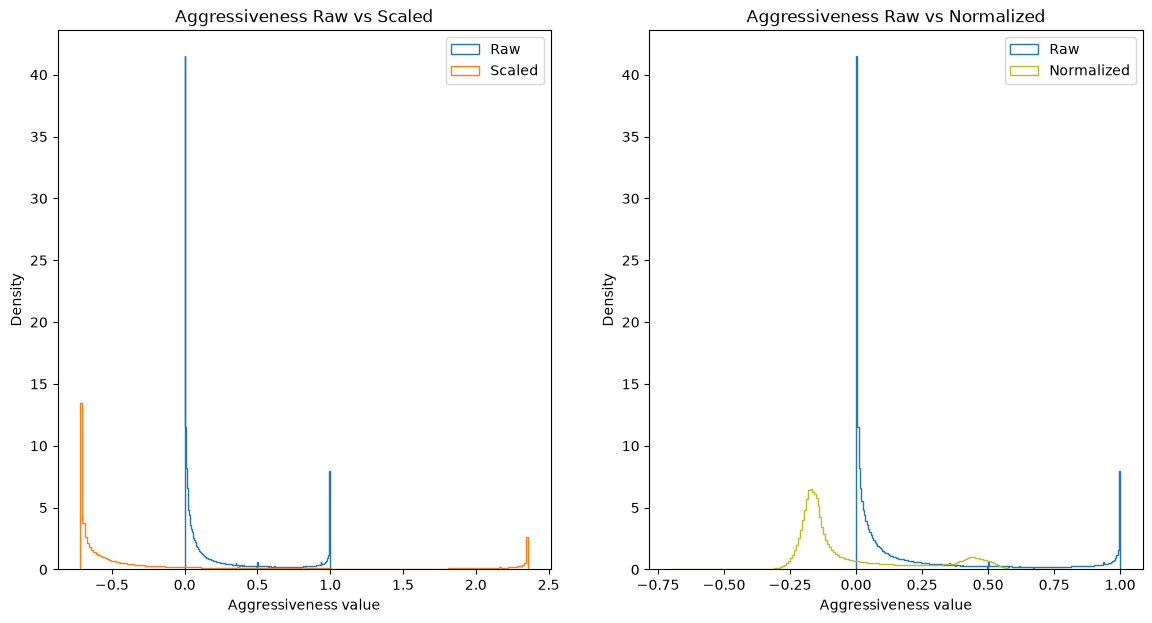

In [13]:
# Compare aggressiveness histogram between raw, scaled and normalized matrices
aggr_raw = features_raw[:, feature_names == "aggressiveness"].ravel()
aggr_scaled = features_scaled[:, feature_names == "aggressiveness"].ravel()
aggr_normalized = features_norm[:, feature_names == "aggressiveness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    aggr_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[0].hist(
    aggr_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Aggressiveness Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    aggr_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[1].hist(
    aggr_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Aggressiveness Raw vs Normalized")
axes[1].legend()

for axis in axes:
    axis.set_xlabel("Aggressiveness value")
    axis.set_ylabel("Density")
plt.show()

In [14]:
aggr_stats_df = pd.DataFrame({
    "min": [aggr_raw.min(), aggr_scaled.min(), aggr_normalized.min()],
    "max": [aggr_raw.max(), aggr_scaled.max(), aggr_normalized.max()],
    "mean": [aggr_raw.mean(), aggr_scaled.mean(), aggr_normalized.mean()],
    "std": [aggr_raw.std(), aggr_scaled.std(), aggr_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(Markdown("**Basic stats for aggressiveness**"))
    display(aggr_stats_df)

**Basic stats for aggressiveness**

,min,max,mean,std
raw,0.0000000,0.9999999,0.2333535,0.3246807
scaled,-0.7187169,2.3612320,-0.0000000,1.0000000
normalized,-0.6975428,0.7930633,-0.0187296,0.2333831


In [15]:
near_zero = (aggr_raw < 0.01).mean() * 100
nearish_zero = (aggr_raw < 0.1).mean() * 100
near_one = (aggr_raw > 0.99).mean() * 100
nearish_one = (aggr_raw > 0.9).mean() * 100
uncertain = ((aggr_raw > 0.4) & (aggr_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.01: {fg.GREEN}{near_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.99: {fg.GREEN}{near_one:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Between 0.4 and 0.6: {fg.MAGENTA}{uncertain:.2f}%{fg.RESET}")

Below 0.01: 26.52%
Below 0.10: 57.74%
Above 0.99: 4.78%
Above 0.90: 9.70%
Between 0.4 and 0.6: 5.67%


In [16]:
# Check the aggressiveness of known tracks
aggressive_data = []

for mbid in aggressive_mbids:
    bytes = np.frombuffer(uuid.UUID(mbid).bytes, dtype="V16", count=1)[0]
    index = np.where(feature_store["mbids"] == bytes)[0][0]

    track = Track.objects.filter(musicbrainz_recordingid=mbid).prefetch_related("artists").first()
    if not track:
        continue

    artists = ", ".join(artist.name for artist in track.artists.all())

    aggressive_data.append({
        "title": track.title, "artists": artists,
        "raw": aggr_raw[index], "scaled": aggr_scaled[index], "norm": aggr_normalized[index],
        # "mbid": mbid
    })

aggr_df = pd.DataFrame(aggressive_data)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}The merged aggressiveness values for known tracks \
- based on feature matrix contents{style.RESET_ALL}")
with pd.option_context('display.float_format', lambda x: f'{x:,.5f}'):
    display(aggr_df)

The merged aggressiveness values for known tracks - based on feature matrix contents


,title,artists,raw,scaled,norm
0,Enter Sandman,Metallica,0.38244,0.45917,0.10736
1,Hells Bells,AC/DC,0.83881,1.86476,0.49275
2,Hearts on Fire,HammerFall,0.83165,1.84271,0.34440
3,Burning Times,Iced Earth,0.98049,2.30113,0.43948
4,Bad Medicine,Bon Jovi,0.96319,2.24787,0.49326
5,2 Minutes to Midnight,Iron Maiden,0.99951,2.35972,0.50102
6,Ace of Spades,Motörhead,0.99675,2.35122,0.45494
7,Bed of Roses,Bon Jovi,0.07709,-0.48129,-0.15179
8,Bohemian Rhapsody,Queen,0.11360,-0.36883,-0.16050
9,Nothing Else Matters,Metallica,0.00001,-0.71868,-0.24272


In [17]:
df = export_stats(feature_stats, feature="mood_aggressive", target_mbids=aggressive_mbids)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}Aggressiveness stats based on duplicate submissions found \
in the original dataset{style.RESET_ALL}")

print(f"{style.BRIGHT}Predictions{style.RESET_ALL}")
display(df[["title", "artists", "total_pred", "aggressive_count", "not_aggressive_count"]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}aggressive{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_aggressive_mean", "tagged_aggressive_median", "tagged_aggressive_std"
]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}not_aggressive{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_not_aggressive_mean", "tagged_not_aggressive_median",
    "tagged_not_aggressive_std"
]])

print(f"{style.BRIGHT}Statistics for all submissions (regardless of tag)")
display(df[[
    "title", "artists", "all_aggressive_mean", "all_aggressive_median", "all_aggressive_std",
    "all_not_aggressive_mean", "all_not_aggressive_median", "all_not_aggressive_std"
]])

Aggressiveness stats based on duplicate submissions found in the original dataset
Predictions


,title,artists,total_pred,aggressive_count,not_aggressive_count
0,Enter Sandman,Metallica,189,63,125
1,Hells Bells,AC/DC,487,444,43
2,Hearts on Fire,HammerFall,35,35,0
3,Burning Times,Iced Earth,7,6,1
4,Bad Medicine,Bon Jovi,290,279,11
5,2 Minutes to Midnight,Iron Maiden,17,16,1
6,Ace of Spades,Motörhead,238,232,6
7,Bed of Roses,Bon Jovi,345,1,344
8,Bohemian Rhapsody,Queen,389,0,389
9,Nothing Else Matters,Metallica,188,9,179


Statistics for submissions tagged aggressive


,title,artists,tagged_aggressive_mean,tagged_aggressive_median,tagged_aggressive_std
0,Enter Sandman,Metallica,0.909786,1.000000,0.165806
1,Hells Bells,AC/DC,0.841295,0.838818,0.071202
2,Hearts on Fire,HammerFall,0.856104,0.831645,0.051807
3,Burning Times,Iced Earth,0.980109,0.980806,0.002037
4,Bad Medicine,Bon Jovi,0.948451,0.964253,0.051537
5,2 Minutes to Midnight,Iron Maiden,0.999512,0.999508,0.000038
6,Ace of Spades,Motörhead,0.995519,0.996756,0.004599
7,Bed of Roses,Bon Jovi,NaN,NaN,NaN
8,Bohemian Rhapsody,Queen,NaN,NaN,NaN
9,Nothing Else Matters,Metallica,0.987621,0.988995,0.002335


Statistics for submissions tagged not_aggressive


,title,artists,tagged_not_aggressive_mean,tagged_not_aggressive_median,tagged_not_aggressive_std
0,Enter Sandman,Metallica,0.660365,0.645783,0.108598
1,Hells Bells,AC/DC,0.864993,0.930961,0.141375
2,Hearts on Fire,HammerFall,NaN,NaN,NaN
3,Burning Times,Iced Earth,NaN,NaN,NaN
4,Bad Medicine,Bon Jovi,0.899280,0.940569,0.093334
5,2 Minutes to Midnight,Iron Maiden,NaN,NaN,NaN
6,Ace of Spades,Motörhead,1.000000,1.000000,0.000000
7,Bed of Roses,Bon Jovi,0.919746,0.922912,0.033311
8,Bohemian Rhapsody,Queen,0.879444,0.886403,0.033134
9,Nothing Else Matters,Metallica,0.992270,0.999990,0.038272


Statistics for all submissions (regardless of tag)


,title,artists,all_aggressive_mean,all_aggressive_median,all_aggressive_std,all_not_aggressive_mean,all_not_aggressive_median,all_not_aggressive_std
0,Enter Sandman,Metallica,0.530534,0.382437,0.298797,0.469466,0.617563,0.298797
1,Hells Bells,AC/DC,0.778933,0.838809,0.215842,0.221067,0.161191,0.215842
2,Hearts on Fire,HammerFall,0.856104,0.831645,0.051807,0.143896,0.168355,0.051807
3,Burning Times,Iced Earth,0.840093,0.980486,0.370451,0.159907,0.019514,0.370451
4,Bad Medicine,Bon Jovi,0.916295,0.963194,0.170799,0.083705,0.036806,0.170799
5,2 Minutes to Midnight,Iron Maiden,0.940718,0.999508,0.242417,0.059282,0.000492,0.242417
6,Ace of Spades,Motörhead,0.970422,0.996749,0.156455,0.029578,0.003251,0.156455
7,Bed of Roses,Bon Jovi,0.082920,0.077088,0.059652,0.917080,0.922912,0.059652
8,Bohemian Rhapsody,Queen,0.120556,0.113597,0.033134,0.879444,0.886403,0.033134
9,Nothing Else Matters,Metallica,0.054639,0.000014,0.213060,0.945361,0.999986,0.213060


##### Conclusions

Like danceability, aggressiveness is also clustered at the extremes. We could assume that most features are like this going forward but we should verify.

Around $57\%$ of the values are less than $0.1$ indicating that most tracks don't have an aggressive mood. 
Manual inspection has shown that the feature is accurate: popular heavy-metal tracks rank high in aggressiveness while rock ballads rank low.

The low mean confirms that most values a closer to 0 than 1. Compared to the mean, the relatively large standard deviation indicates that there are large number of tracks scattered across the range, especially at the upper limit.

**Choice of method for merging duplicates**

Something warranting further investigation is "Enter Sandman" which despite being a well-known heavy metal anthem, received a low aggressiveness prediction. It might be that the slower nursery-rhyme segments confuse classifiers. Separate investigation has shown that predictions are split between aggressive / not aggressive. Each time a prediction was made, it had high average confidence for aggressive.

It's not clear that merging duplicate submissions using a median is the right choice. We should investigate if this pattern of conflicting predictions reoccurs.

#### Happiness

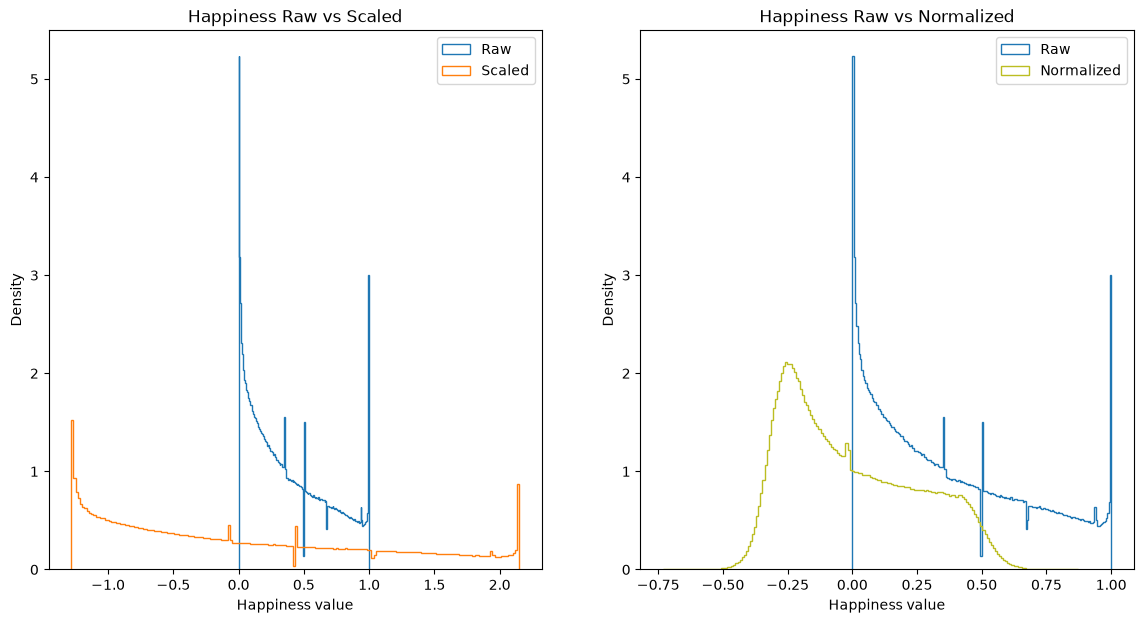

In [18]:
# Compare happiness histogram between raw, scaled and normalized matrices
happy_raw = features_raw[:, feature_names == "happiness"].ravel()
happy_scaled = features_scaled[:, feature_names == "happiness"].ravel()
happy_normalized = features_norm[:, feature_names == "happiness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    happy_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[0].hist(
    happy_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Happiness Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    happy_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[1].hist(
    happy_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Happiness Raw vs Normalized")
axes[1].legend()

for axis in axes:
    axis.set_xlabel("Happiness value")
    axis.set_ylabel("Density")
plt.show()

In [19]:
happy_stats_df = pd.DataFrame({
    "min": [happy_raw.min(), happy_scaled.min(), happy_normalized.min()],
    "max": [happy_raw.max(), happy_scaled.max(), happy_normalized.max()],
    "mean": [happy_raw.mean(), happy_scaled.mean(), happy_normalized.mean()],
    "std": [happy_raw.std(), happy_scaled.std(), happy_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(Markdown("**Basic stats for happiness**"))
    display(happy_stats_df)

**Basic stats for happiness**

,min,max,mean,std
raw,0.0000000,0.9999999,0.3737697,0.2911601
scaled,-1.2837256,2.1508107,0.0000000,1.0000000
normalized,-0.7320766,0.8713605,-0.0037761,0.2557331


In [20]:
near_zero = (happy_raw < 0.01).mean() * 100
nearish_zero = (happy_raw < 0.1).mean() * 100
near_one = (happy_raw > 0.99).mean() * 100
nearish_one = (happy_raw > 0.9).mean() * 100
uncertain = ((happy_raw > 0.4) & (happy_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.01: {fg.GREEN}{near_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.99: {fg.GREEN}{near_one:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Between 0.4 and 0.6: {fg.MAGENTA}{uncertain:.2f}%{fg.RESET}")

Below 0.01: 4.21%
Below 0.10: 21.96%
Above 0.99: 1.85%
Above 0.90: 6.30%
Between 0.4 and 0.6: 16.34%


In [21]:
# Check the happiness of known tracks
happy_data = []

for mbid in happy_mbids:
    mbid_bytes = np.frombuffer(uuid.UUID(mbid).bytes, dtype="V16", count=1)[0]
    index = np.where(feature_store["mbids"] == mbid_bytes)[0][0]

    track = Track.objects.filter(musicbrainz_recordingid=mbid).prefetch_related("artists").first()
    if not track:
        continue

    artists = ", ".join(artist.name for artist in track.artists.all())

    happy_data.append({
        "title": track.title, "artists": artists, "submissions": track.submissions,
        "raw": happy_raw[index], "scaled": happy_scaled[index], "norm": happy_normalized[index],
        "mbid": mbid
    })

happy_df = pd.DataFrame(happy_data)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}The merged happiness values for known tracks \
- based on feature matrix contents{style.RESET_ALL}")
with pd.option_context('display.float_format', lambda x: f'{x:,.5f}'):
    display(happy_df)

The merged happiness values for known tracks - based on feature matrix contents


,title,artists,submissions,raw,scaled,norm,mbid
0,Happy,Pharrell Williams,320,0.37849,0.01621,0.00571,f367ad6e-efd5-4496-aba5-21a4edcd82c6
1,Don't Stop Me Now,Queen,283,0.69353,1.09822,0.32682,d4009c09-a339-4b89-bc45-d91ab649acb6
2,Walking on Sunshine,Katrina and the Waves,259,0.69157,1.09149,0.26952,2138bf67-fe08-46d3-863d-560e1b8c3043
3,Good Vibrations,The Beach Boys,182,0.18416,-0.65123,-0.22426,3ad31947-ae54-4409-aeaa-8dbd16c3825f
4,Here Comes the Sun,The Beatles,483,0.50000,0.43354,0.13529,440f60e8-0b25-4ec4-abb1-c6beec624ab0
5,Mr. Blue Sky,Electric Light Orchestra,278,0.61013,0.81180,0.26891,6e33056b-2a34-4ed0-b49c-f7a8ae2c5bcc
6,Lovely Day,Bill Withers,238,0.55853,0.63455,0.16881,2d6daa5a-19d9-4254-b149-26f162c4634f
7,Hurt,Johnny Cash,248,0.18376,-0.65259,-0.15289,25d8de5e-3662-4ffd-8dea-511a696ac3e7
8,Mad World,Gary Jules,29,0.50677,0.45680,0.16070,49eb0679-0a3d-4be5-9adf-973cd429b9a7
9,Tears In Heaven,Eric Clapton,174,0.31512,-0.20143,-0.05403,bc10b379-413a-49d9-b6a5-36771762c4d3


In [22]:
df = export_stats(feature_stats, feature="mood_happy", target_mbids=happy_mbids)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}Happiness stats based on duplicate submissions found \
in the original dataset{style.RESET_ALL}")

print(f"{style.BRIGHT}Predictions{style.RESET_ALL}")
display(df[["title", "artists", "total_pred", "happy_count", "not_happy_count"]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}happy{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_happy_mean", "tagged_happy_median", "tagged_happy_std"
]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}not_happy{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_not_happy_mean", "tagged_not_happy_median",
    "tagged_not_happy_std"
]])

print(f"{style.BRIGHT}Statistics for all submissions (regardless of tag)")
display(df[[
    "title", "artists", "all_happy_mean", "all_happy_median", "all_happy_std",
    "all_not_happy_mean", "all_not_happy_median", "all_not_happy_std"
]])

Happiness stats based on duplicate submissions found in the original dataset
Predictions


,title,artists,total_pred,happy_count,not_happy_count
0,Happy,Pharrell Williams,326,35,289
1,Don't Stop Me Now,Queen,287,281,6
2,Walking on Sunshine,Katrina and the Waves,261,239,18
3,Good Vibrations,The Beach Boys,182,7,175
4,Here Comes the Sun,The Beatles,484,242,232
5,Mr. Blue Sky,Electric Light Orchestra,280,275,4
6,Lovely Day,Bill Withers,239,220,13
7,Hurt,Johnny Cash,251,4,247
8,Mad World,Gary Jules,30,16,11
9,Tears In Heaven,Eric Clapton,175,82,93


Statistics for submissions tagged happy


,title,artists,tagged_happy_mean,tagged_happy_median,tagged_happy_std
0,Happy,Pharrell Williams,0.529046,0.511861,0.037457
1,Don't Stop Me Now,Queen,0.700528,0.693818,0.087693
2,Walking on Sunshine,Katrina and the Waves,0.717270,0.703142,0.111913
3,Good Vibrations,The Beach Boys,0.616102,0.551515,0.143330
4,Here Comes the Sun,The Beatles,0.728824,0.790851,0.144868
5,Mr. Blue Sky,Electric Light Orchestra,0.634528,0.610219,0.066607
6,Lovely Day,Bill Withers,0.616797,0.558597,0.119236
7,Hurt,Johnny Cash,0.769195,0.714733,0.157092
8,Mad World,Gary Jules,0.545295,0.550146,0.032789
9,Tears In Heaven,Eric Clapton,0.655344,0.660689,0.052702


Statistics for submissions tagged not_happy


,title,artists,tagged_not_happy_mean,tagged_not_happy_median,tagged_not_happy_std
0,Happy,Pharrell Williams,0.637077,0.628470,0.065775
1,Don't Stop Me Now,Queen,0.593487,0.546315,0.093296
2,Walking on Sunshine,Katrina and the Waves,0.559260,0.519047,0.086095
3,Good Vibrations,The Beach Boys,0.781678,0.821197,0.101973
4,Here Comes the Sun,The Beatles,0.637740,0.641777,0.059291
5,Mr. Blue Sky,Electric Light Orchestra,0.812679,0.835664,0.110137
6,Lovely Day,Bill Withers,0.595384,0.563180,0.081643
7,Hurt,Johnny Cash,0.796567,0.819899,0.045807
8,Mad World,Gary Jules,0.646637,0.594012,0.110206
9,Tears In Heaven,Eric Clapton,0.758417,0.763109,0.067930


Statistics for all submissions (regardless of tag)


,title,artists,all_happy_mean,all_happy_median,all_happy_std,all_not_happy_mean,all_not_happy_median,all_not_happy_std
0,Happy,Pharrell Williams,0.381599,0.378331,0.081965,0.618401,0.621669,0.081965
1,Don't Stop Me Now,Queen,0.694382,0.693554,0.097244,0.305618,0.306446,0.097244
2,Walking on Sunshine,Katrina and the Waves,0.694870,0.691567,0.132159,0.305130,0.308433,0.132159
3,Good Vibrations,The Beach Boys,0.233621,0.184158,0.128691,0.766379,0.815842,0.128691
4,Here Comes the Sun,The Beatles,0.548388,0.503072,0.212495,0.451612,0.496928,0.212495
5,Mr. Blue Sky,Electric Light Orchestra,0.627659,0.610132,0.085861,0.372341,0.389868,0.085861
6,Lovely Day,Bill Withers,0.602324,0.558525,0.126535,0.397676,0.441475,0.126535
7,Hurt,Johnny Cash,0.212449,0.184919,0.086027,0.787551,0.815081,0.086027
8,Mad World,Gary Jules,0.470390,0.506825,0.114565,0.529610,0.493175,0.114565
9,Tears In Heaven,Eric Clapton,0.435460,0.316594,0.215890,0.564540,0.683406,0.215890


##### Conclusions

Happiness is much less concentrated at the extremes than the previous features: only $6.06\%$ of raw values are below $0.01$ or above $0.99$, while $71.74\%$ lie between $0.1$ and $0.9$. The earlier assumption that most features would be clustered at the endpoints does not hold here.

The known-track check gives some counterintuitive scores: 
- *Pharrell Williams' "Happy"* is $0.378$ and *The Beach Boys' "Good Vibrations"* is $0.184$, while Gary Jules' "Mad World" is $0.507$. 
- For *"Happy"*, the source predictions also lean strongly toward `not_happy`: $289$ votes versus $35$ happy votes, with 2 ties. These examples warrant a listening check before relying on the feature to rank tracks by perceived happiness.

*TL;DR Good spread, mid usefulness.*

#### Sadness
It represents the fact the the song has a sad mood or not. It's not the mathematical inverse of the `happiness` feature.

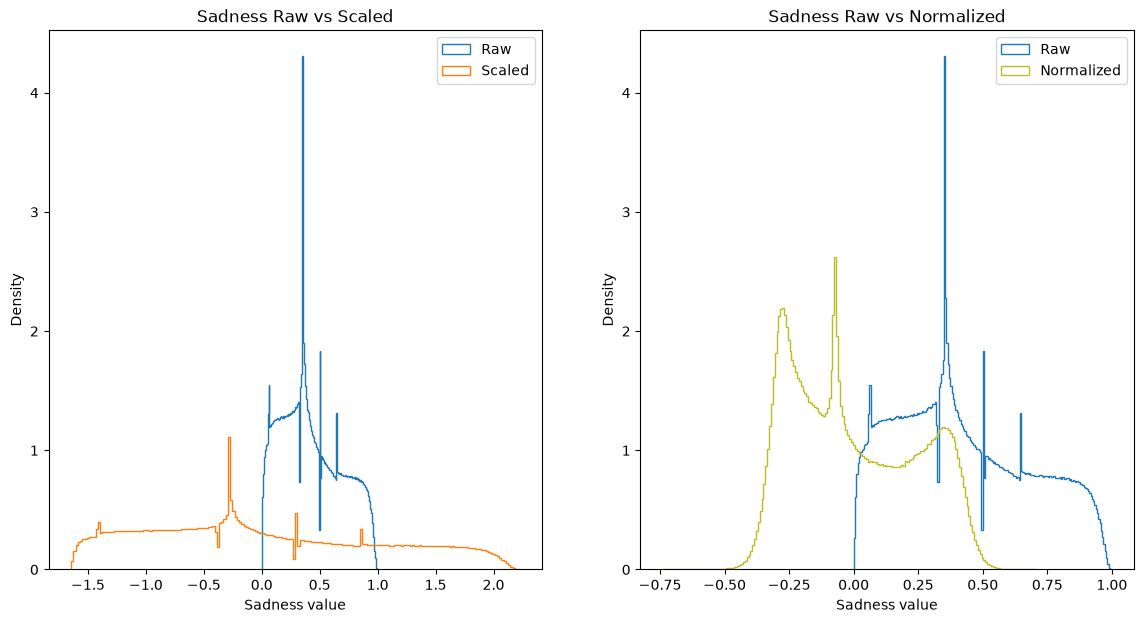

In [23]:
# Compare sadness histogram between raw, scaled and normalized matrices
sad_raw = features_raw[:, feature_names == "sadness"].ravel()
sad_scaled = features_scaled[:, feature_names == "sadness"].ravel()
sad_normalized = features_norm[:, feature_names == "sadness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(
    sad_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[0].hist(
    sad_scaled, bins=200, density=True, histtype="step", color="tab:orange", label="Scaled",
)
axes[0].set_title("Sadness Raw vs Scaled")
axes[0].legend()

axes[1].hist(
    sad_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw",
)
axes[1].hist(
    sad_normalized, bins=200, density=True, histtype="step", color="tab:olive", label="Normalized",
)
axes[1].set_title("Sadness Raw vs Normalized")
axes[1].legend()

for axis in axes:
    axis.set_xlabel("Sadness value")
    axis.set_ylabel("Density")
plt.show()

In [24]:
sad_stats_df = pd.DataFrame({
    "min": [sad_raw.min(), sad_scaled.min(), sad_normalized.min()],
    "max": [sad_raw.max(), sad_scaled.max(), sad_normalized.max()],
    "mean": [sad_raw.mean(), sad_scaled.mean(), sad_normalized.mean()],
    "std": [sad_raw.std(), sad_scaled.std(), sad_normalized.std()]
}, index=["raw", "scaled", "normalized"])

with pd.option_context('display.float_format', lambda x: f'{x:,.7f}'):
    display(Markdown("**Basic stats for sadness**"))
    display(sad_stats_df)

**Basic stats for sadness**

,min,max,mean,std
raw,0.0004773,0.9972335,0.4244918,0.2576384
scaled,-1.6457739,2.2230444,0.0000000,1.0000000
normalized,-0.7390817,0.7043973,-0.0007592,0.2401341


In [25]:
near_zero = (sad_raw < 0.01).mean() * 100
nearish_zero = (sad_raw < 0.1).mean() * 100
near_one = (sad_raw > 0.99).mean() * 100
nearish_one = (sad_raw > 0.9).mean() * 100
uncertain = ((sad_raw > 0.4) & (sad_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.01: {fg.GREEN}{near_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.99: {fg.GREEN}{near_one:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Between 0.4 and 0.6: {fg.MAGENTA}{uncertain:.2f}%{fg.RESET}")

Below 0.01: 0.40%
Below 0.10: 10.48%
Above 0.99: 0.00%
Above 0.90: 3.78%
Between 0.4 and 0.6: 20.02%


In [26]:
happiness_raw = features_raw[:, feature_names == "happiness"].ravel()
sad_happy_correlation = np.corrcoef(sad_raw, happiness_raw)[0, 1]
both_high = ((sad_raw > 0.5) & (happiness_raw > 0.5)).mean() * 100
both_low = ((sad_raw < 0.5) & (happiness_raw < 0.5)).mean() * 100

print(f"Pearson correlation with happiness: {sad_happy_correlation:.3f}")
print(f"{fg.WHITE}Both probabilities above 0.5: {fg.GREEN}{both_high:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Both probabilities below 0.5: {fg.GREEN}{both_low:.2f}%{fg.RESET}")

Pearson correlation with happiness: -0.150
Both probabilities above 0.5: 9.13%
Both probabilities below 0.5: 40.53%


In [27]:
# Check the sadness of known tracks
sad_data = []

for mbid in sad_mbids:
    mbid_bytes = np.frombuffer(uuid.UUID(mbid).bytes, dtype="V16", count=1)[0]
    index = np.where(feature_store["mbids"] == mbid_bytes)[0][0]

    track = Track.objects.filter(musicbrainz_recordingid=mbid).prefetch_related("artists").first()
    if not track:
        continue

    artists = ", ".join(artist.name for artist in track.artists.all())

    sad_data.append({
        "title": track.title, "artists": artists, "submissions": track.submissions,
        "raw": sad_raw[index], "happiness": happiness_raw[index],
        "scaled": sad_scaled[index], "norm": sad_normalized[index],
        # "mbid": mbid
    })

sad_df = pd.DataFrame(sad_data)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}The merged sadness values for known tracks \
- based on feature matrix contents{style.RESET_ALL}")
with pd.option_context('display.float_format', lambda x: f'{x:,.5f}'):
    display(sad_df)

The merged sadness values for known tracks - based on feature matrix contents


,title,artists,submissions,raw,happiness,scaled,norm
0,Hurt,Johnny Cash,248,0.90117,0.18376,1.85018,0.43348
1,Everybody Hurts,R.E.M.,304,0.83048,0.10387,1.57582,0.40158
2,Someone Like You,Adele,434,0.75533,0.62826,1.28411,0.31041
3,Nothing Compares 2 U,Sinéad O'Connor,259,0.54974,0.45464,0.48614,0.14834
4,Tears In Heaven,Eric Clapton,174,0.70100,0.31512,1.07322,0.28786
5,Mad World,Gary Jules,29,0.48964,0.50677,0.25287,0.08896
6,The Scientist,Coldplay,303,0.48064,0.83744,0.21794,0.06396
7,River,Joni Mitchell,113,0.91858,0.05319,1.91776,0.42421
8,Happy,Pharrell Williams,320,0.26095,0.37849,-0.63476,-0.22353
9,Don't Stop Me Now,Queen,283,0.24644,0.69353,-0.69111,-0.20567


In [28]:
df = export_stats(feature_stats, feature="mood_sad", target_mbids=sad_mbids)

print(f"{bg.BLACK}{style.BRIGHT}{fg.GREEN}Sadness stats based on duplicate submissions found \
in the original dataset{style.RESET_ALL}")

print(f"{style.BRIGHT}Predictions{style.RESET_ALL}")
display(df[["title", "artists", "total_pred", "sad_count", "not_sad_count"]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}sad{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_sad_mean", "tagged_sad_median", "tagged_sad_std"
]])

print(f"{style.BRIGHT}Statistics for submissions tagged {fg.GREEN}not_sad{style.RESET_ALL}")
display(df[[
    "title", "artists", "tagged_not_sad_mean", "tagged_not_sad_median",
    "tagged_not_sad_std"
]])

print(f"{style.BRIGHT}Statistics for all submissions (regardless of tag)")
display(df[[
    "title", "artists", "all_sad_mean", "all_sad_median", "all_sad_std",
    "all_not_sad_mean", "all_not_sad_median", "all_not_sad_std"
]])

Sadness stats based on duplicate submissions found in the original dataset
Predictions


,title,artists,total_pred,sad_count,not_sad_count
0,Happy,Pharrell Williams,326,5,321
1,Don't Stop Me Now,Queen,287,0,287
2,Good Vibrations,The Beach Boys,182,1,181
3,Hurt,Johnny Cash,251,251,0
4,Mad World,Gary Jules,30,12,17
5,Tears In Heaven,Eric Clapton,175,165,10
6,Everybody Hurts,R.E.M.,307,283,24
7,Someone Like You,Adele,437,423,14
8,Nothing Compares 2 U,Sinéad O'Connor,259,238,9
9,The Scientist,Coldplay,303,107,194


Statistics for submissions tagged sad


,title,artists,tagged_sad_mean,tagged_sad_median,tagged_sad_std
0,Happy,Pharrell Williams,0.804930,0.803904,0.001733
1,Don't Stop Me Now,Queen,NaN,NaN,NaN
2,Good Vibrations,The Beach Boys,NaN,NaN,NaN
3,Hurt,Johnny Cash,0.885292,0.901168,0.039339
4,Mad World,Gary Jules,0.599328,0.556136,0.108088
5,Tears In Heaven,Eric Clapton,0.710516,0.713983,0.071111
6,Everybody Hurts,R.E.M.,0.829409,0.833851,0.040890
7,Someone Like You,Adele,0.752362,0.755581,0.026443
8,Nothing Compares 2 U,Sinéad O'Connor,0.560232,0.553041,0.037052
9,The Scientist,Coldplay,0.509381,0.506987,0.009119


Statistics for submissions tagged not_sad


,title,artists,tagged_not_sad_mean,tagged_not_sad_median,tagged_not_sad_std
0,Happy,Pharrell Williams,0.734107,0.739067,0.032464
1,Don't Stop Me Now,Queen,0.753545,0.753572,0.031672
2,Good Vibrations,The Beach Boys,0.677190,0.665999,0.048926
3,Hurt,Johnny Cash,NaN,NaN,NaN
4,Mad World,Gary Jules,0.609211,0.597385,0.075306
5,Tears In Heaven,Eric Clapton,0.585177,0.612570,0.035369
6,Everybody Hurts,R.E.M.,0.583094,0.517295,0.106694
7,Someone Like You,Adele,0.635758,0.629768,0.051978
8,Nothing Compares 2 U,Sinéad O'Connor,0.532103,0.515320,0.042766
9,The Scientist,Coldplay,0.541234,0.540173,0.023378


Statistics for all submissions (regardless of tag)


,title,artists,all_sad_mean,all_sad_median,all_sad_std,all_not_sad_mean,all_not_sad_median,all_not_sad_std
0,Happy,Pharrell Williams,0.274160,0.260949,0.073752,0.725840,0.739051,0.073752
1,Don't Stop Me Now,Queen,0.246455,0.246428,0.031672,0.753545,0.753572,0.031672
2,Good Vibrations,The Beach Boys,0.324553,0.334001,0.054158,0.675447,0.665999,0.054158
3,Hurt,Johnny Cash,0.885292,0.901168,0.039339,0.114708,0.098833,0.039339
4,Mad World,Gary Jules,0.477845,0.485893,0.134636,0.522155,0.514107,0.134636
5,Tears In Heaven,Eric Clapton,0.693619,0.698876,0.097820,0.306381,0.301124,0.097820
6,Everybody Hurts,R.E.M.,0.797161,0.830455,0.121239,0.202839,0.169545,0.121239
7,Someone Like You,Adele,0.739927,0.755311,0.073752,0.260073,0.244689,0.073752
8,Nothing Compares 2 U,Sinéad O'Connor,0.554232,0.549740,0.041807,0.445768,0.450260,0.041807
9,The Scientist,Coldplay,0.476912,0.480642,0.031097,0.523088,0.519358,0.031097


##### Conclusions

Sadness and happiness are distinct metrics determined in different ways. Their raw probabilities have only a weak negative correlation ($r = -0.150$). Both exceed $0.5$ for $9.13\%$ of tracks, while both fall below $0.5$ for $40.53\%$. They should be treated as separate signals when filtering or weighting recommendations.

The known-track check illustrates this overlap: *Adele's "Someone Like You"* scores $0.755$ for sadness and $0.628$ for happiness. *Johnny Cash's "Hurt"* scores $0.901$ for sadness, with all $251$ source predictions labelled `sad`. *R.E.M.'s "Everybody Hurts"* scores $0.830$, while *Gary Jules' "Mad World"* sits close to the decision boundary at $0.490$.

Overall `sadness` looks like a decent feature. It's not clustered at the extremes and gives scores that are close to expectations. The strength of those scores isn't very big but it's in the right direction.

#### Relaxedness

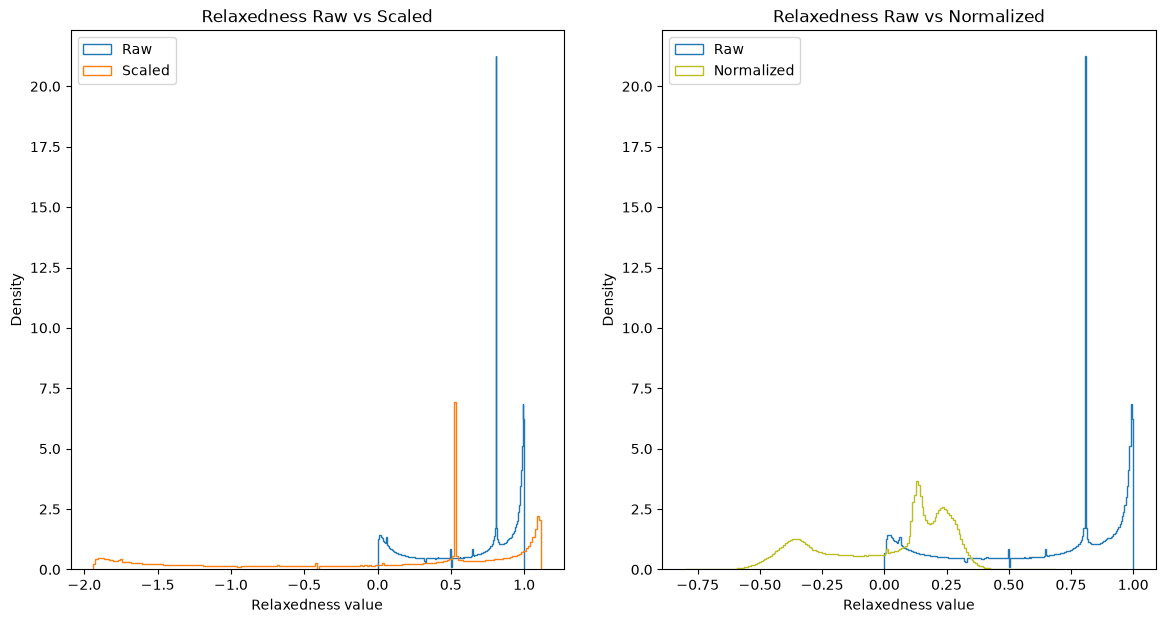

In [29]:
relaxed_raw = features_raw[:, feature_names == "relaxedness"].ravel()
relaxed_scaled = features_scaled[:, feature_names == "relaxedness"].ravel()
relaxed_normalized = features_norm[:, feature_names == "relaxedness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
comparisons = [
    ("Scaled", relaxed_scaled, "tab:orange"),
    ("Normalized", relaxed_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(
        relaxed_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
    )
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Relaxedness Raw vs {label}", xlabel="Relaxedness value", ylabel="Density")
    axis.legend()
plt.show()

In [30]:
relaxed_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (relaxed_raw, relaxed_scaled, relaxed_normalized)
    ],
    index=["raw", "scaled", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for relaxedness**"))
with pd.option_context("display.float_format", "{:,.7f}".format):
    display(relaxed_stats_df)

**Basic stats for relaxedness**

,min,max,mean,median,std
raw,0.0003335,1.0000000,0.6346848,0.7890396,0.3269144
scaled,-1.9404204,1.1174644,-0.0000000,0.4721566,1.0000000
normalized,-0.8015997,0.6847759,0.0088021,0.1157716,0.2530358


In [31]:
nearish_zero = (relaxed_raw < 0.1).mean() * 100
between_50_60 = ((relaxed_raw > 0.70) & (relaxed_raw < 0.90)).mean() * 100
above_60 = (relaxed_raw > 0.60).mean() * 100
nearish_one = (relaxed_raw > 0.9).mean() * 100
midrange = ((relaxed_raw > 0.4) & (relaxed_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.60: {fg.GREEN}{above_60:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Between 0.70 and 0.90: {fg.GREEN}{between_50_60:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Between 0.4 and 0.6: {fg.MAGENTA}{midrange:.2f}%{fg.RESET}")

Below 0.10: 11.16%
Above 0.60: 63.11%
Between 0.70 and 0.90: 30.66%
Above 0.90: 26.64%
Between 0.4 and 0.6: 9.66%


In [32]:
# Check the relaxedness of known tracks
relaxed_tracks = Track.objects.prefetch_related("artists").in_bulk(relaxed_mbids)
matrix_mbids = feature_store["mbids"]
relaxed_data = []

for mbid in relaxed_mbids:
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    index = np.flatnonzero(matrix_mbids == mbid_bytes)[0]
    track = relaxed_tracks[mbid]
    artists = ", ".join(artist.name for artist in track.artists.all())
    relaxed_data.append({
        "title": track.title,
        "artists": artists,
        "submissions": track.submissions,
        "raw": relaxed_raw[index],
        "scaled": relaxed_scaled[index],
        "norm": relaxed_normalized[index],
    })

relaxed_df = pd.DataFrame(relaxed_data)

display(Markdown("**Merged relaxedness scores for selected tracks**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(relaxed_df)

**Merged relaxedness scores for selected tracks**

,title,artists,submissions,raw,scaled,norm
0,Blue in Green,Miles Davis,233,0.95185,0.97019,0.30120
1,An Ending (Ascent),Brian Eno,87,0.99087,1.08954,0.25069
2,Watermark,Enya,228,0.99702,1.10836,0.30149
3,Clair De Lune,Claude Debussy,35,0.99065,1.08886,0.22106
4,Come Away With Me,Norah Jones,170,0.96098,0.99811,0.18433
5,Better Together,Jack Johnson,142,0.97755,1.04878,0.29163
6,La Femme d'argent,Air,138,0.96264,1.00317,0.32381
7,Territorial Pissings,Nirvana,226,0.00741,-1.91876,-0.33672
8,Firestarter,The Prodigy,152,0.42314,-0.64708,-0.16380
9,Raining Blood,Slayer,47,0.57903,-0.17023,-0.04080


In [33]:
relaxed_submission_stats = export_stats(
    feature_stats, feature="mood_relaxed", target_mbids=relaxed_mbids
)

display(Markdown("**Relaxedness predictions from source submissions**"))
display(relaxed_submission_stats[["title", "artists", "total_pred", "relaxed_count", "not_relaxed_count"]])

display(Markdown("**Statistics for submissions tagged relaxed**"))
display(relaxed_submission_stats[[
    "title", "artists", "tagged_relaxed_mean", "tagged_relaxed_median", "tagged_relaxed_std",
]])

display(Markdown("**Statistics for submissions tagged not relaxed**"))
display(relaxed_submission_stats[[
    "title", "artists", "tagged_not_relaxed_mean", "tagged_not_relaxed_median", "tagged_not_relaxed_std",
]])

display(Markdown("**Statistics across all submissions**"))
display(relaxed_submission_stats[[
    "title", "artists", "all_relaxed_mean", "all_relaxed_median", "all_relaxed_std",
    "all_not_relaxed_mean", "all_not_relaxed_median", "all_not_relaxed_std",
]])

**Relaxedness predictions from source submissions**

,title,artists,total_pred,relaxed_count,not_relaxed_count
0,Blue in Green,Miles Davis,234,234,0
1,An Ending (Ascent),Brian Eno,87,87,0
2,Watermark,Enya,231,229,2
3,Clair De Lune,Claude Debussy,35,35,0
4,Come Away With Me,Norah Jones,171,171,0
5,Better Together,Jack Johnson,143,143,0
6,La Femme d'argent,Air,138,138,0
7,Territorial Pissings,Nirvana,226,10,216
8,Firestarter,The Prodigy,153,38,111
9,Raining Blood,Slayer,47,40,7


**Statistics for submissions tagged relaxed**

,title,artists,tagged_relaxed_mean,tagged_relaxed_median,tagged_relaxed_std
0,Blue in Green,Miles Davis,0.939543,0.951835,4.088725e-02
1,An Ending (Ascent),Brian Eno,0.973439,0.990872,5.276592e-02
2,Watermark,Enya,0.974713,0.997024,6.282945e-02
3,Clair De Lune,Claude Debussy,0.980492,0.990650,3.203135e-02
4,Come Away With Me,Norah Jones,0.942506,0.960979,5.641609e-02
5,Better Together,Jack Johnson,0.963884,0.977545,5.759298e-02
6,La Femme d'argent,Air,0.958482,0.962636,3.019371e-02
7,Territorial Pissings,Nirvana,0.808817,0.808817,3.769729e-07
8,Firestarter,The Prodigy,0.639990,0.617172,1.112683e-01
9,Raining Blood,Slayer,0.585438,0.579040,6.953805e-02


**Statistics for submissions tagged not relaxed**

,title,artists,tagged_not_relaxed_mean,tagged_not_relaxed_median,tagged_not_relaxed_std
0,Blue in Green,Miles Davis,NaN,NaN,NaN
1,An Ending (Ascent),Brian Eno,NaN,NaN,NaN
2,Watermark,Enya,0.991214,0.991214,2.950276e-07
3,Clair De Lune,Claude Debussy,NaN,NaN,NaN
4,Come Away With Me,Norah Jones,NaN,NaN,NaN
5,Better Together,Jack Johnson,NaN,NaN,NaN
6,La Femme d'argent,Air,NaN,NaN,NaN
7,Territorial Pissings,Nirvana,0.987990,0.992731,2.778644e-02
8,Firestarter,The Prodigy,0.606515,0.592863,6.052920e-02
9,Raining Blood,Slayer,0.700875,0.575846,1.845337e-01


**Statistics across all submissions**

,title,artists,all_relaxed_mean,all_relaxed_median,all_relaxed_std,all_not_relaxed_mean,all_not_relaxed_median,all_not_relaxed_std
0,Blue in Green,Miles Davis,0.939543,0.951835,0.040887,0.060457,0.048165,0.040887
1,An Ending (Ascent),Brian Eno,0.973439,0.990872,0.052766,0.026561,0.009128,0.052766
2,Watermark,Enya,0.966350,0.997023,0.109344,0.033650,0.002977,0.109344
3,Clair De Lune,Claude Debussy,0.980492,0.990650,0.032031,0.019508,0.009350,0.032031
4,Come Away With Me,Norah Jones,0.942506,0.960979,0.056416,0.057494,0.039021,0.056416
5,Better Together,Jack Johnson,0.963884,0.977545,0.057593,0.036116,0.022455,0.057593
6,La Femme d'argent,Air,0.958482,0.962636,0.030194,0.041518,0.037364,0.030194
7,Territorial Pissings,Nirvana,0.047267,0.007413,0.166454,0.952733,0.992587,0.166454
8,Firestarter,The Prodigy,0.457493,0.419441,0.130503,0.542507,0.580558,0.130503
9,Raining Blood,Slayer,0.542796,0.579033,0.138412,0.457204,0.420967,0.138412


##### Conclusions

Relaxedness scores lean high. The raw median is $0.789$, and $26.64\%$ of recordings score above $0.90$. About $7.47\%$ fall below $0.01$ or above $0.99$, so relaxedness is less concentrated at the endpoints than danceability or aggressiveness.

The seven calm examples score between $0.952$ and $0.997$. For other tracks:
- Nirvana's "Territorial Pissings" scores $0.007$
- Slayer's "Raining Blood" scores $0.579$.

The calm examples make relaxedness promising as a soft recommendation preference, since most of the scores are likely to be high.

#### Partyness

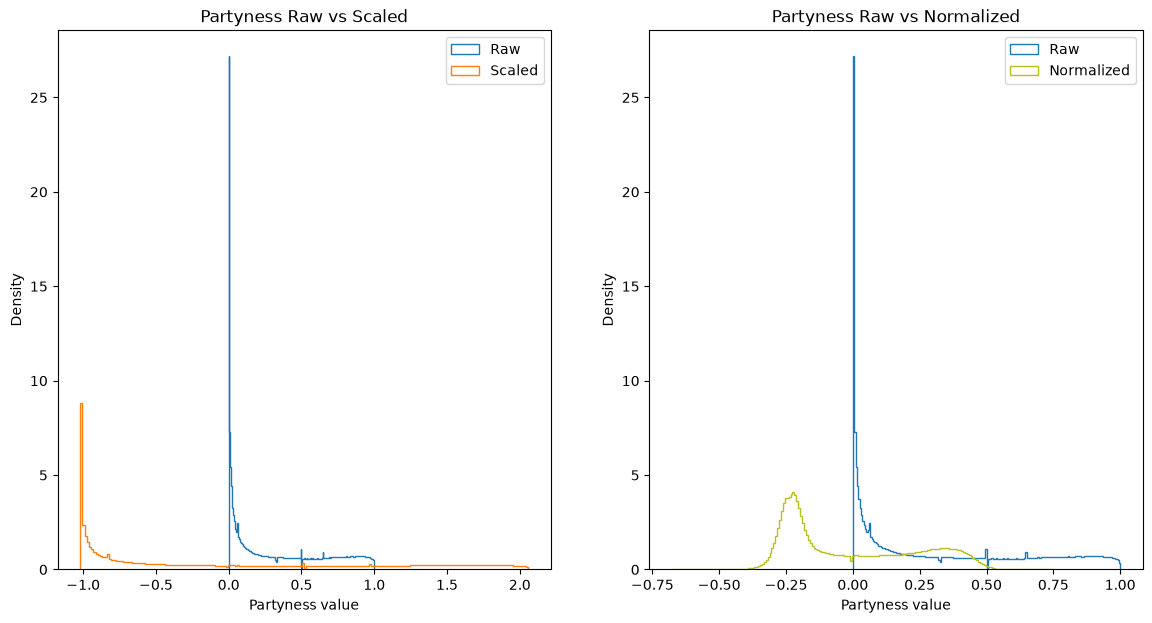

In [34]:
party_raw = features_raw[:, feature_names == "partyness"].ravel()
party_scaled = features_scaled[:, feature_names == "partyness"].ravel()
party_normalized = features_norm[:, feature_names == "partyness"].ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
comparisons = [
    ("Scaled", party_scaled, "tab:orange"),
    ("Normalized", party_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(
        party_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
    )
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Partyness Raw vs {label}", xlabel="Partyness value", ylabel="Density")
    axis.legend()
plt.show()

In [35]:
party_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (party_raw, party_scaled, party_normalized)
    ],
    index=["raw", "scaled", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for partyness**"))
with pd.option_context("display.float_format", "{:,.7f}".format):
    display(party_stats_df)

**Basic stats for partyness**

,min,max,mean,median,std
raw,0.0000001,1.0000000,0.3316139,0.2161362,0.3246341
scaled,-1.0215002,2.0588903,-0.0000000,-0.3557165,1.0000000
normalized,-0.6770305,0.7553625,-0.0086127,-0.1023502,0.2489049


In [36]:
near_zero = (party_raw < 0.01).mean() * 100
nearish_zero = (party_raw < 0.1).mean() * 100
below_midpoint = (party_raw < 0.5).mean() * 100
near_one = (party_raw > 0.99).mean() * 100
nearish_one = (party_raw > 0.9).mean() * 100
midrange = ((party_raw > 0.4) & (party_raw < 0.6)).mean() * 100

print(f"{fg.WHITE}Below 0.01: {fg.GREEN}{near_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.10: {fg.GREEN}{nearish_zero:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Below 0.50: {fg.GREEN}{below_midpoint:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.99: {fg.GREEN}{near_one:.2f}%{fg.RESET}")
print(f"{fg.WHITE}Above 0.90: {fg.GREEN}{nearish_one:.2f}%{fg.RESET}")
print(f"Between 0.4 and 0.6: {fg.MAGENTA}{midrange:.2f}%{fg.RESET}")

Below 0.01: 17.23%
Below 0.10: 39.04%
Below 0.50: 67.90%
Above 0.99: 0.42%
Above 0.90: 6.37%
Between 0.4 and 0.6: 11.84%


In [37]:
# Check the partyness of selected tracks
party_tracks = Track.objects.prefetch_related("artists").in_bulk(party_mbids)
matrix_mbids = feature_store["mbids"]
party_data = []

for mbid in party_mbids:
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    index = np.flatnonzero(matrix_mbids == mbid_bytes)[0]
    track = party_tracks[mbid]
    artists = ", ".join(artist.name for artist in track.artists.all())
    party_data.append({
        "title": track.title,
        "artists": artists,
        "submissions": track.submissions,
        "raw": party_raw[index],
        "scaled": party_scaled[index],
        "norm": party_normalized[index],
    })

party_df = pd.DataFrame(party_data)

display(Markdown("**Merged partyness scores for selected tracks (feature matrix)**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(party_df)

**Merged partyness scores for selected tracks (feature matrix)**

,title,artists,submissions,raw,scaled,norm
0,Party Rock Anthem,LMFAO,320,0.88575,1.70697,0.40123
1,Celebration,Kool & The Gang,141,0.69846,1.13004,0.40598
2,Yeah!,Usher,180,0.94072,1.87628,0.51920
3,Don't Stop the Music,Rihanna,223,0.92152,1.81715,0.47453
4,Get the Party Started,P!nk,377,0.92286,1.82128,0.42625
5,Just Dance,Lady Gaga,412,0.46953,0.42482,0.14078
6,I Gotta Feeling,The Black Eyed Peas,442,0.24654,-0.26206,-0.08989
7,On the Nature of Daylight,Max Richter,37,0.04922,-0.86989,-0.24644
8,Strange Fruit,Billie Holiday,91,0.00980,-0.99132,-0.21220
9,Gymnopédie no. 1,Erik Satie,25,0.00058,-1.01972,-0.20984


In [38]:
party_submission_stats = export_stats(
    feature_stats, feature="mood_party", target_mbids=party_mbids
)

display(Markdown("**Partyness predictions from source submissions**"))
display(party_submission_stats[["title", "artists", "total_pred", "party_count", "not_party_count"]])

display(Markdown("**Statistics for submissions tagged party**"))
display(party_submission_stats[[
    "title", "artists", "tagged_party_mean", "tagged_party_median", "tagged_party_std",
]])

display(Markdown("**Statistics for submissions tagged not party**"))
display(party_submission_stats[[
    "title", "artists", "tagged_not_party_mean", "tagged_not_party_median", "tagged_not_party_std",
]])

display(Markdown("**Statistics across all submissions**"))
display(party_submission_stats[[
    "title", "artists", "all_party_mean", "all_party_median", "all_party_std",
    "all_not_party_mean", "all_not_party_median", "all_not_party_std",
]])

**Partyness predictions from source submissions**

,title,artists,total_pred,party_count,not_party_count
0,Party Rock Anthem,LMFAO,332,315,17
1,Celebration,Kool & The Gang,141,95,46
2,Yeah!,Usher,181,177,4
3,Don't Stop the Music,Rihanna,225,219,6
4,Get the Party Started,P!nk,379,369,10
5,Just Dance,Lady Gaga,416,138,274
6,I Gotta Feeling,The Black Eyed Peas,442,30,412
7,On the Nature of Daylight,Max Richter,37,0,37
8,Strange Fruit,Billie Holiday,91,0,91
9,Gymnopédie no. 1,Erik Satie,25,0,25


**Statistics for submissions tagged party**

,title,artists,tagged_party_mean,tagged_party_median,tagged_party_std
0,Party Rock Anthem,LMFAO,0.866509,0.887873,0.077947
1,Celebration,Kool & The Gang,0.731268,0.752813,0.074714
2,Yeah!,Usher,0.942870,0.941040,0.026063
3,Don't Stop the Music,Rihanna,0.924886,0.921531,0.025657
4,Get the Party Started,P!nk,0.923454,0.922990,0.017875
5,Just Dance,Lady Gaga,0.616819,0.613314,0.085920
6,I Gotta Feeling,The Black Eyed Peas,0.791528,0.806952,0.108266
7,On the Nature of Daylight,Max Richter,NaN,NaN,NaN
8,Strange Fruit,Billie Holiday,NaN,NaN,NaN
9,Gymnopédie no. 1,Erik Satie,NaN,NaN,NaN


**Statistics for submissions tagged not party**

,title,artists,tagged_not_party_mean,tagged_not_party_median,tagged_not_party_std
0,Party Rock Anthem,LMFAO,0.832827,0.997020,0.187290
1,Celebration,Kool & The Gang,0.991109,0.997342,0.017675
2,Yeah!,Usher,0.999760,0.999984,0.000448
3,Don't Stop the Music,Rihanna,0.984288,0.999984,0.038426
4,Get the Party Started,P!nk,0.887227,0.999795,0.149330
5,Just Dance,Lady Gaga,0.563311,0.534595,0.101233
6,I Gotta Feeling,The Black Eyed Peas,0.733381,0.761848,0.074943
7,On the Nature of Daylight,Max Richter,0.948254,0.950782,0.014232
8,Strange Fruit,Billie Holiday,0.982663,0.990204,0.029740
9,Gymnopédie no. 1,Erik Satie,0.999422,0.999421,0.000007


**Statistics across all submissions**

,title,artists,all_party_mean,all_party_median,all_party_std,all_not_party_mean,all_not_party_median,all_not_party_std
0,Party Rock Anthem,LMFAO,0.830699,0.875920,0.176894,0.169301,0.124080,0.176894
1,Celebration,Kool & The Gang,0.495599,0.698464,0.345499,0.504401,0.301536,0.345499
2,Yeah!,Usher,0.922039,0.940720,0.141327,0.077961,0.059280,0.141327
3,Don't Stop the Music,Rihanna,0.900641,0.921523,0.149078,0.099359,0.078477,0.149078
4,Get the Party Started,P!nk,0.902064,0.922873,0.133303,0.097936,0.077127,0.133303
5,Just Dance,Lady Gaga,0.497053,0.469593,0.127884,0.502947,0.530407,0.127884
6,I Gotta Feeling,The Black Eyed Peas,0.302246,0.246540,0.153221,0.697754,0.753460,0.153221
7,On the Nature of Daylight,Max Richter,0.051746,0.049218,0.014232,0.948254,0.950782,0.014232
8,Strange Fruit,Billie Holiday,0.017337,0.009796,0.029740,0.982663,0.990204,0.029740
9,Gymnopédie no. 1,Erik Satie,0.000578,0.000579,0.000007,0.999422,0.999421,0.000007


##### Conclusions

Raw `partyness` scores lean low. The median is $0.216$, and $67.90\%$ of recordings score below $0.50$. About $39.04\%$ score below $0.10$, and $6.37\%$ score above $0.90$.

Five of the seven party examples score between $0.698$ and $0.941$, and the three contrasting tracks score below $0.05$. 
- *Lady Gaga's "Just Dance"* scores $0.470$
- *The Black Eyed Peas' "I Gotta Feeling"* scores $0.247$, with only $30$ of $442$ valid source predictions tagged party.

In this set, a cutoff of $0.50$ would miss two recognizable party tracks.

#### Acousticness

Prediction for if a recording has an acoustic mood. I omitted the positive vs negative prediction comparisons as they didn't add much value in above steps. We can include them if there's a significant number of outliers.

Added a check for how studio and acoustic versions of the same songs compare, alongside other well-known acoustic, electronic, and hybrid examples.

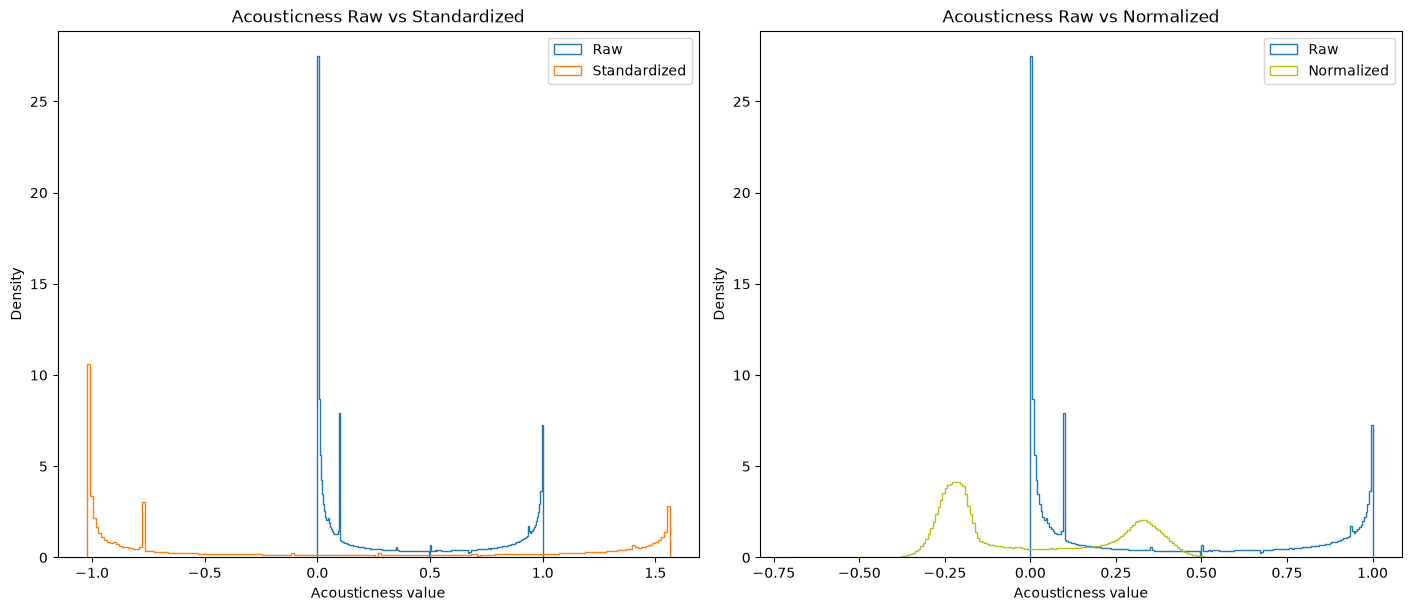

In [39]:
acoustic_col = np.flatnonzero(feature_names == "acousticness")[0]
acoustic_raw = features_raw[:, acoustic_col]
acoustic_scaled = features_scaled[:, acoustic_col]
acoustic_normalized = features_norm[:, acoustic_col]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
comparisons = [
    ("Standardized", acoustic_scaled, "tab:orange"),
    ("Normalized", acoustic_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(
        acoustic_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
    )
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Acousticness Raw vs {label}", xlabel="Acousticness value", ylabel="Density")
    axis.legend()
plt.show()

In [40]:
acoustic_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (acoustic_raw, acoustic_scaled, acoustic_normalized)
    ],
    index=["raw", "standardized", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for acousticness**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(acoustic_stats_df)

acoustic_raw_shares = pd.Series({
    "Below 0.01": (acoustic_raw < 0.01).mean(),
    "Below 0.10": (acoustic_raw < 0.10).mean(),
    "At or above 0.50": (acoustic_raw >= 0.50).mean(),
    "Above 0.90": (acoustic_raw > 0.90).mean(),
    "Above 0.99": (acoustic_raw > 0.99).mean(),
}, name="Share of recordings")
display(acoustic_raw_shares.to_frame().style.format("{:.2%}"))

**Basic stats for acousticness**

,min,max,mean,median,std
raw,0.00000,1.00000,0.39563,0.22976,0.38655
standardized,-1.02348,1.56349,-0.00000,-0.42910,1.00000
normalized,-0.70372,0.73782,-0.00042,-0.12302,0.25561


,Share of recordings
Below 0.01,18.10%
Below 0.10,41.33%
At or above 0.50,39.17%
Above 0.90,19.43%
Above 0.99,5.46%


In [41]:
acoustic_tracks = Track.objects.select_related("album").prefetch_related("artists").in_bulk(acoustic_mbids)
matrix_mbids = feature_store["mbids"]
acoustic_rows = []
for mbid, example in acoustic_examples.items():
    track = acoustic_tracks.get(mbid)
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    indices = np.flatnonzero(matrix_mbids == mbid_bytes)
    if track is None or indices.size == 0:
        print(f"Recording {mbid} is missing from the database or feature matrix.")
        continue
    index = indices[0]
    acoustic_rows.append({
        "type": example,
        "title": track.title,
        "artists": ", ".join(artist.name for artist in track.artists.all()),
        "album": track.album.name if track.album else None,
        "submissions": track.submissions,
        "raw": acoustic_raw[index],
        "standardized": acoustic_scaled[index],
        "normalized": acoustic_normalized[index],
    })

acoustic_df = pd.DataFrame(acoustic_rows)
display(Markdown("**Merged acousticness scores for selected recordings**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(acoustic_df)

**Merged acousticness scores for selected recordings**

,type,title,artists,album,submissions,raw,standardized,normalized
0,Studio,Come as You Are,Nirvana,Nevermind,298,0.01351,-0.98853,-0.21986
1,Unplugged,Come as You Are,Nirvana,MTV Unplugged,137,0.46519,0.17994,0.08794
2,Studio,Creep,Radiohead,Pablo Honey,146,0.01400,-0.98727,-0.27598
3,Acoustic version,Creep (acoustic),Radiohead,Itch,72,0.99589,1.55287,0.35520
4,Acoustic,Blue in Green,Miles Davis,Lincoln Center NY 1964,233,0.93799,1.40308,0.43559
5,Acoustic,Strange Fruit,Billie Holiday,Billie Holiday,91,0.98606,1.52743,0.32695
6,Acoustic,Gymnopédie no. 1,Erik Satie,The 50 Greatest Pieces of Classical Music,25,0.99998,1.56344,0.32173
7,Acoustic,Blackbird,The Beatles,The Beatles,291,0.99664,1.55478,0.31705
8,Electronic,One More Time,Daft Punk,Discovery,438,0.00001,-1.02346,-0.31986
9,Electronic,Firestarter,The Prodigy,The Fat of the Land,152,0.00642,-1.00688,-0.25488


In [42]:
# Keep the source table in the same order as the selected examples.
acoustic_stats_by_mbid = {mbid: feature_stats.get(mbid, {}) for mbid in acoustic_mbids}
acoustic_submission_stats = export_stats(acoustic_stats_by_mbid, feature="mood_acoustic")
acoustic_submission_stats.insert(0, "example", list(acoustic_examples.values()))

display(Markdown("**Acousticness predictions from source submissions**"))
display(acoustic_submission_stats[[
    "example", "title", "artists", "total_pred", "acoustic_count", "not_acoustic_count",
]])

display(Markdown("**Acoustic scores across all valid source submissions**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(acoustic_submission_stats[[
        "example", "title", "artists", "all_acoustic_mean", "all_acoustic_median", "all_acoustic_std",
    ]])

**Acousticness predictions from source submissions**

,example,title,artists,total_pred,acoustic_count,not_acoustic_count
0,Studio,Come as You Are,Nirvana,303,0,302
1,Unplugged,Come as You Are,Nirvana,137,7,109
2,Studio,Creep,Radiohead,146,0,146
3,Acoustic version,Creep (acoustic),Radiohead,72,68,4
4,Acoustic,Blue in Green,Miles Davis,234,218,16
5,Acoustic,Strange Fruit,Billie Holiday,91,91,0
6,Acoustic,Gymnopédie no. 1,Erik Satie,25,25,0
7,Acoustic,Blackbird,The Beatles,294,289,5
8,Electronic,One More Time,Daft Punk,438,0,438
9,Electronic,Firestarter,The Prodigy,153,0,153


**Acoustic scores across all valid source submissions**

,example,title,artists,all_acoustic_mean,all_acoustic_median,all_acoustic_std
0,Studio,Come as You Are,Nirvana,0.02053,0.01351,0.03287
1,Unplugged,Come as You Are,Nirvana,0.45189,0.46519,0.09357
2,Studio,Creep,Radiohead,0.01644,0.01400,0.01434
3,Acoustic version,Creep (acoustic),Radiohead,0.94536,0.99589,0.21013
4,Acoustic,Blue in Green,Miles Davis,0.88112,0.93800,0.21500
5,Acoustic,Strange Fruit,Billie Holiday,0.97710,0.98606,0.03292
6,Acoustic,Gymnopédie no. 1,Erik Satie,0.99998,0.99998,0.00000
7,Acoustic,Blackbird,The Beatles,0.97031,0.99664,0.13137
8,Electronic,One More Time,Daft Punk,0.03004,0.00001,0.05983
9,Electronic,Firestarter,The Prodigy,0.01301,0.00642,0.02205


##### Conclusions

Raw acousticness has a median of $0.230$. About $41.33\%$ of scores fell below $0.10$ and $19.43\%$ exceeded $0.90$. The extremes are uneven, with $18.10\%$ below $0.01$ and $5.46\%$ above $0.99$. Vector normalization reduced the standard deviation from $1.000$ after standardization to $0.256$.

Both paired examples scored higher in their acoustic versions. 
- Radiohead's *Creep* went from $0.014$ to $0.996$, with $68$ of $72$ predictions tagged acoustic for the acoustic version. 
- Nirvana's *Come as You Are* went from $0.014$ to $0.465$. Of the $137$ unplugged predictions, $7$ favored acoustic and $21$ were ties. A raw cutoff of $0.50$ would exclude that unplugged performance.

The downside is that hybrid arrangements can score high too. Air's *La Femme d’argent* scored $0.885$ and Portishead's *The Rip* scored $0.931$.

TL;DR Decent feature, clustered at extremes.

#### Electronicness

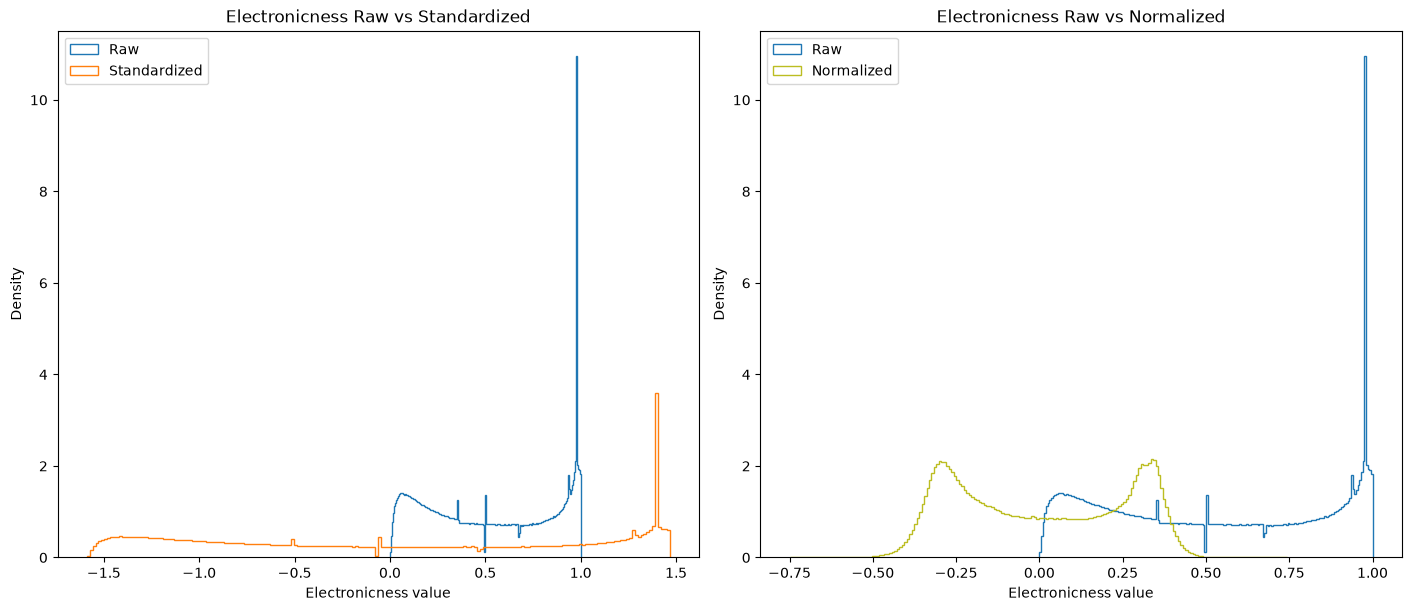

In [43]:
electronic_col = np.flatnonzero(feature_names == "electronicness")[0]
electronic_raw = features_raw[:, electronic_col]
electronic_scaled = features_scaled[:, electronic_col]
electronic_normalized = features_norm[:, electronic_col]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
comparisons = [
    ("Standardized", electronic_scaled, "tab:orange"),
    ("Normalized", electronic_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(
        electronic_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
    )
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Electronicness Raw vs {label}", xlabel="Electronicness value", ylabel="Density")
    axis.legend()
plt.show()

In [44]:
electronic_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (electronic_raw, electronic_scaled, electronic_normalized)
    ],
    index=["raw", "standardized", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for electronicness**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(electronic_stats_df)

electronic_raw_shares = pd.Series({
    "Below 0.01": (electronic_raw < 0.01).mean(),
    "Below 0.10": (electronic_raw < 0.10).mean(),
    "At or above 0.50": (electronic_raw >= 0.50).mean(),
    "Above 0.90": (electronic_raw > 0.90).mean(),
    "Above 0.99": (electronic_raw > 0.99).mean(),
}, name="Share of recordings")
display(electronic_raw_shares.to_frame().style.format("{:.2%}"))

**Basic stats for electronicness**

,min,max,mean,median,std
raw,0.00000,1.00000,0.52012,0.50683,0.32725
standardized,-1.58937,1.46640,-0.00000,-0.04061,1.00000
normalized,-0.74979,0.74462,0.00453,-0.01144,0.25543


,Share of recordings
Below 0.01,0.29%
Below 0.10,11.87%
At or above 0.50,50.81%
Above 0.90,20.12%
Above 0.99,1.86%


In [45]:
electronic_tracks = Track.objects.select_related("album").prefetch_related("artists").in_bulk(electronic_mbids)
electronic_rows = []
for mbid, example in electronic_examples.items():
    track = electronic_tracks.get(mbid)
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    indices = np.flatnonzero(matrix_mbids == mbid_bytes)
    if track is None or indices.size == 0:
        print(f"Recording {mbid} is missing from the database or feature matrix.")
        continue
    index = indices[0]
    electronic_rows.append({
        "type": example,
        "title": track.title,
        "artists": ", ".join(artist.name for artist in track.artists.all()),
        "album": track.album.name if track.album else None,
        "submissions": track.submissions,
        "raw electronicness": electronic_raw[index],
        "standardized electronicness": electronic_scaled[index],
        "normalized electronicness": electronic_normalized[index],
    })

electronic_df = pd.DataFrame(electronic_rows)
display(Markdown("**Merged electronicness scores for selected recordings**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(electronic_df)

**Merged electronicness scores for selected recordings**

,type,title,artists,album,submissions,raw electronicness,standardized electronicness,normalized electronicness
0,Electronic,Hyperballad,Björk,373 # Post,201,0.90252,1.16854,0.34943
1,String quartet version,Hyperballad (Brodsky Quartet version),Björk,Telegram,35,0.02896,-1.50087,-0.40877
2,Electronic,Take On Me,a-ha,Hunting High and Low,377,0.18801,-1.01485,-0.24008
3,Unplugged,Take On Me (MTV Unplugged - Summer Solstice),a-ha,Deadpool 2 (Original Motion Picture Soundtrack),135,0.07924,-1.34722,-0.28718
4,Electronic,The Robots,Kraftwerk,The Man·Machine,155,0.88120,1.10339,0.35963
5,Electronic,One More Time,Daft Punk,Discovery,438,0.94045,1.28443,0.40142
6,Electronic,Popcorn,Hot Butter,Popcorn,116,0.34842,-0.52469,-0.12933
7,Acoustic,Gymnopédie no. 1,Erik Satie,The 50 Greatest Pieces of Classical Music,25,0.00950,-1.56035,-0.32109
8,Amplified rock,Come as You Are,Nirvana,Nevermind,298,0.25032,-0.82445,-0.18337
9,Hybrid,La Femme d'argent,Air,Moon Safari,138,0.59367,0.22474,0.07254


In [46]:
# Keep the source table in the same order as the selected examples.
electronic_stats_by_mbid = {mbid: feature_stats.get(mbid, {}) for mbid in electronic_mbids}
electronic_submission_stats = export_stats(electronic_stats_by_mbid, feature="mood_electronic")
electronic_submission_stats.insert(0, "type", list(electronic_examples.values()))

display(Markdown("**Electronicness predictions from source submissions**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(electronic_submission_stats[[
        "type", "title", "artists", "total_pred", "electronic_count", "not_electronic_count",
        "all_electronic_median", "all_electronic_std",
    ]])

**Electronicness predictions from source submissions**

,type,title,artists,total_pred,electronic_count,not_electronic_count,all_electronic_median,all_electronic_std
0,Electronic,Hyperballad,Björk,201,201,0,0.90252,0.02157
1,String quartet version,Hyperballad (Brodsky Quartet version),Björk,35,3,32,0.02896,0.26066
2,Electronic,Take On Me,a-ha,384,12,372,0.18801,0.14531
3,Unplugged,Take On Me (MTV Unplugged - Summer Solstice),a-ha,135,0,135,0.07924,0.00472
4,Electronic,The Robots,Kraftwerk,163,163,0,0.88121,0.06075
5,Electronic,One More Time,Daft Punk,438,403,35,0.94045,0.16684
6,Electronic,Popcorn,Hot Butter,116,16,100,0.34842,0.17698
7,Acoustic,Gymnopédie no. 1,Erik Satie,25,0,25,0.00950,0.00069
8,Amplified rock,Come as You Are,Nirvana,303,15,288,0.25051,0.15604
9,Hybrid,La Femme d'argent,Air,138,136,2,0.59367,0.07976


##### Conclusions

Raw electronicness had a median of $0.507$. About $50.81\%$ of recordings scored at least $0.50$, $11.87\%$ scored below $0.10$, and $20.12\%$ scored above $0.90$. Vector normalization reduced the standard deviation from $1.000$ after standardization to $0.255$.

Björk's *Hyperballad* scored $0.903$ in the original and $0.029$ in the Brodsky Quartet version. All $201$ valid source predictions for the original favored electronic, compared with $3$ of $35$ for the quartet version. The studio version of a-ha's *Take On Me* scored $0.188$ and only $12$ of $384$ source predictions favored electronic. A raw cutoff of $0.50$ would exclude that synth-pop recording.

#### Instrumentalness

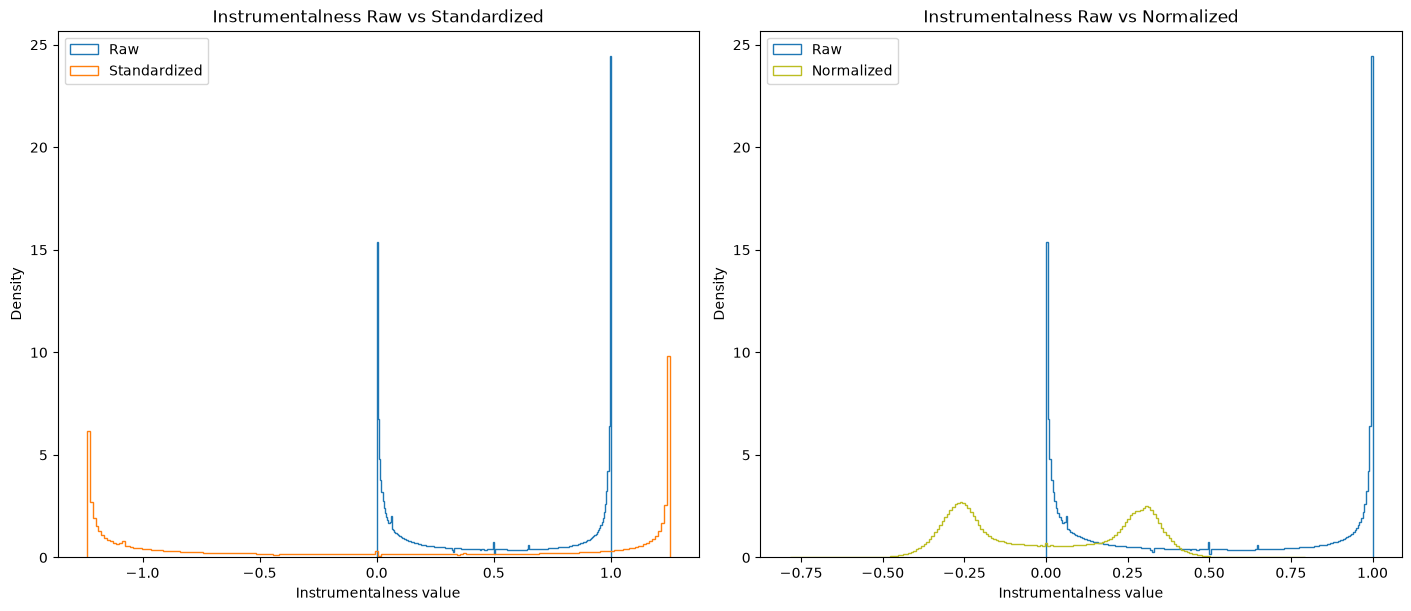

In [47]:
instrumental_col = np.flatnonzero(feature_names == "instrumentalness")[0]
instrumental_raw = features_raw[:, instrumental_col]
instrumental_scaled = features_scaled[:, instrumental_col]
instrumental_normalized = features_norm[:, instrumental_col]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
comparisons = [
    ("Standardized", instrumental_scaled, "tab:orange"),
    ("Normalized", instrumental_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(
        instrumental_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw"
    )
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Instrumentalness Raw vs {label}", xlabel="Instrumentalness value", ylabel="Density")
    axis.legend()
plt.show()

In [48]:
instrumental_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (instrumental_raw, instrumental_scaled, instrumental_normalized)
    ],
    index=["raw", "standardized", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for instrumentalness**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(instrumental_stats_df)

instrumental_raw_shares = pd.Series({
    "Below 0.01": (instrumental_raw < 0.01).mean(),
    "Below 0.10": (instrumental_raw < 0.10).mean(),
    "At or above 0.50": (instrumental_raw >= 0.50).mean(),
    "Above 0.90": (instrumental_raw > 0.90).mean(),
    "Above 0.99": (instrumental_raw > 0.99).mean(),
}, name="Share of recordings")
display(instrumental_raw_shares.to_frame().style.format("{:.2%}"))

**Basic stats for instrumentalness**

,min,max,mean,median,std
raw,0.00000,1.00000,0.49738,0.47651,0.40176
standardized,-1.23801,1.25106,-0.00000,-0.05193,1.00000
normalized,-0.78526,0.79372,0.00570,-0.01415,0.26428


,Share of recordings
Below 0.01,11.09%
Below 0.10,29.52%
At or above 0.50,49.21%
Above 0.90,30.15%
Above 0.99,15.42%


In [49]:
instrumental_tracks = Track.objects.select_related("album").prefetch_related("artists").in_bulk(instrumental_mbids)
instrumental_rows = []
for mbid, example in instrumental_examples.items():
    track = instrumental_tracks.get(mbid)
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    indices = np.flatnonzero(matrix_mbids == mbid_bytes)
    if track is None or indices.size == 0:
        print(f"Recording {mbid} is missing from the database or feature matrix.")
        continue
    index = indices[0]
    instrumental_rows.append({
        "type": example,
        "title": track.title,
        "artists": ", ".join(artist.name for artist in track.artists.all()),
        "album": track.album.name if track.album else None,
        "submissions": track.submissions,
        "raw": instrumental_raw[index],
        "standardized": instrumental_scaled[index],
        "normalized": instrumental_normalized[index],
    })

instrumental_df = pd.DataFrame(instrumental_rows)
display(Markdown("**Merged instrumentalness scores for selected recordings**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(instrumental_df)

**Merged instrumentalness scores for selected recordings**

,type,title,artists,album,submissions,raw,standardized,normalized
0,Vocal version,Firestarter,The Prodigy,The Fat of the Land,152,0.37926,-0.29401,-0.07443
1,Instrumental version,Firestarter (instrumental),The Prodigy,Wipeout 2097: The Soundtrack,50,0.72127,0.55729,0.13772
2,Instrumental,Blue in Green,Miles Davis,Lincoln Center NY 1964,233,0.99483,1.23821,0.38440
3,Instrumental,Gymnopédie no. 1,Erik Satie,The 50 Greatest Pieces of Classical Music,25,1.00000,1.25106,0.25744
4,Sung vocals,Someone Like You,Adele,21,434,0.00855,-1.21674,-0.29413
5,Sung vocals,Strange Fruit,Billie Holiday,Billie Holiday,91,0.89641,0.99321,0.21260
6,Wordless vocals,The Great Gig in the Sky,Pink Floyd,The Dark Side of the Moon,313,0.44692,-0.12560,-0.03406
7,Wordless vocals,Boadicea,Enya,The Celts,178,1.00000,1.25106,0.25600
8,Spoken samples,Frontier Psychiatrist,The Avalanches,Since I Left You,95,0.34730,-0.37356,-0.12302
9,Processed vocals,"Harder, Better, Faster, Stronger",Daft Punk,Discovery,632,0.98248,1.20747,0.32778


In [50]:
# Keep the source table in the same order as the selected examples.
instrumental_stats_by_mbid = {mbid: feature_stats.get(mbid, {}) for mbid in instrumental_mbids}
instrumental_submission_stats = export_stats(instrumental_stats_by_mbid, feature="voice_instrumental")
instrumental_submission_stats.insert(0, "type", list(instrumental_examples.values()))

display(Markdown("**Instrumentalness predictions from source submissions**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(instrumental_submission_stats[[
        "type", "title", "artists", "total_pred", "instrumental_count", "voice_count",
        "all_instrumental_median", "all_instrumental_std",
    ]])

**Instrumentalness predictions from source submissions**

,type,title,artists,total_pred,instrumental_count,voice_count,all_instrumental_median,all_instrumental_std
0,Vocal version,Firestarter,The Prodigy,153,27,126,0.37912,0.19048
1,Instrumental version,Firestarter (instrumental),The Prodigy,50,45,5,0.72127,0.16251
2,Instrumental,Blue in Green,Miles Davis,234,234,0,0.99483,0.01259
3,Instrumental,Gymnopédie no. 1,Erik Satie,25,25,0,1.00000,0.00000
4,Sung vocals,Someone Like You,Adele,437,15,422,0.00855,0.15549
5,Sung vocals,Strange Fruit,Billie Holiday,91,87,4,0.89641,0.13406
6,Wordless vocals,The Great Gig in the Sky,Pink Floyd,315,117,193,0.44692,0.28540
7,Wordless vocals,Boadicea,Enya,178,178,0,1.00000,0.03976
8,Spoken samples,Frontier Psychiatrist,The Avalanches,95,8,81,0.34730,0.20180
9,Processed vocals,"Harder, Better, Faster, Stronger",Daft Punk,635,627,8,0.98249,0.10168


##### Conclusions

Raw instrumentalness scores clustered at both ends. The median was $0.477$, with $29.52\%$ of recordings below $0.10$ and $30.15\%$ above $0.90$. Vector normalization reduced the standard deviation from $1.000$ after standardization to $0.264$.

The instrumental version of The Prodigy's *Firestarter* scored $0.721$, up from $0.379$ for the vocal version. All valid submissions for Miles Davis's *Blue in Green* and Erik Satie's *Gymnopédie no. 1* favored instrumental, while $15$ of $437$ did so for Adele's *Someone Like You*.

Recordings with audible singing can score high. Billie Holiday's *Strange Fruit* scored $0.896$ and Daft Punk's *Harder, Better, Faster, Stronger* scored $0.982$. For two wordless performances, $193$ of $315$ predictions favored voice on Pink Floyd's *The Great Gig in the Sky*, and all $178$ favored instrumental on Enya's *Boadicea*.

TL;DR Mid signal and clustered.

#### Tonality
Whether a recording sounds *tonal* (centered around a key or harmonic center) or *atonal* (lacking a clear tonal center).

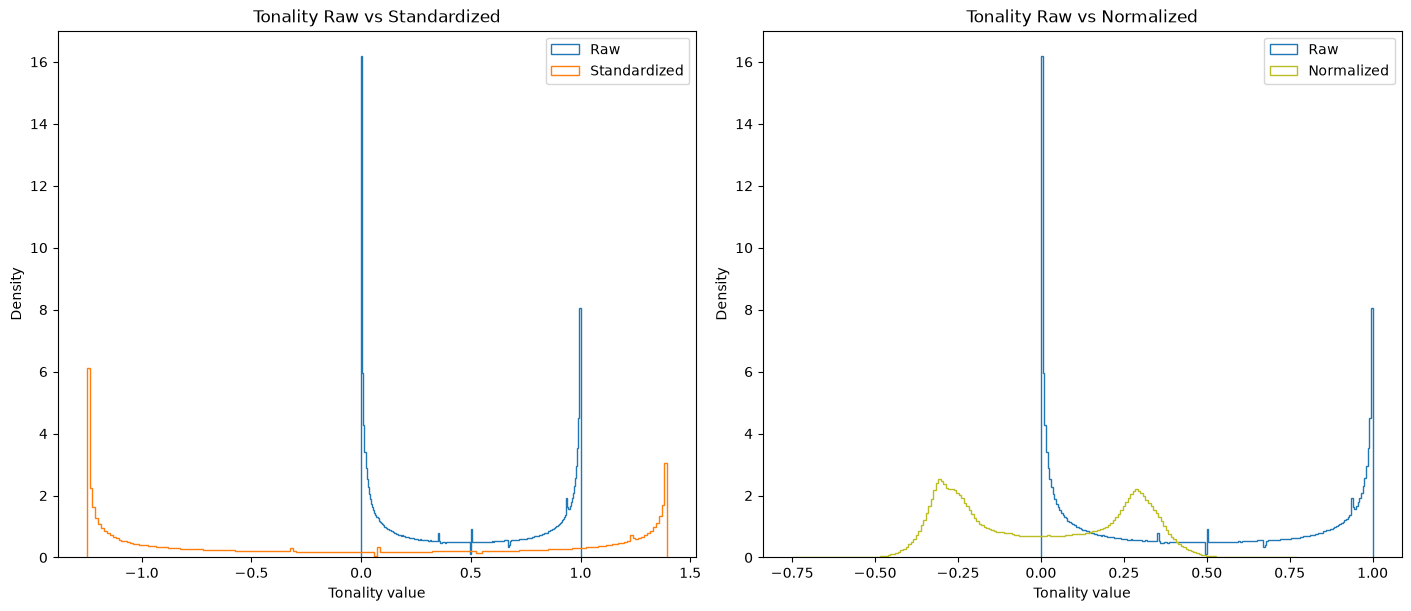

In [51]:
tonal_col = np.flatnonzero(feature_names == "tonality")[0]
tonal_raw = features_raw[:, tonal_col]
tonal_scaled = features_scaled[:, tonal_col]
tonal_normalized = features_norm[:, tonal_col]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
comparisons = [
    ("Standardized", tonal_scaled, "tab:orange"),
    ("Normalized", tonal_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(tonal_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw")
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Tonality Raw vs {label}", xlabel="Tonality value", ylabel="Density")
    axis.legend()
plt.show()

In [52]:
tonal_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (tonal_raw, tonal_scaled, tonal_normalized)
    ],
    index=["raw", "standardized", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for tonality**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(tonal_stats_df)

tonal_raw_shares = pd.Series({
    "Below 0.01": (tonal_raw < 0.01).mean(),
    "Below 0.10": (tonal_raw < 0.10).mean(),
    "At or above 0.50": (tonal_raw >= 0.50).mean(),
    "Above 0.90": (tonal_raw > 0.90).mean(),
    "Above 0.99": (tonal_raw > 0.99).mean(),
}, name="Share of recordings")
display(tonal_raw_shares.to_frame().style.format("{:.2%}"))

**Basic stats for tonality**

,min,max,mean,median,std
raw,0.00000,1.00000,0.47266,0.44590,0.37780
standardized,-1.25109,1.39584,-0.00000,-0.07082,1.00000
normalized,-0.75088,0.77206,-0.00175,-0.01937,0.26196


,Share of recordings
Below 0.01,11.07%
Below 0.10,28.11%
At or above 0.50,47.48%
Above 0.90,22.51%
Above 0.99,6.28%


In [53]:
tonal_tracks = Track.objects.select_related("album").prefetch_related("artists").in_bulk(tonal_mbids)
matrix_mbids = feature_store["mbids"]
tonal_rows = []
for mbid, label in tonal_examples.items():
    track = tonal_tracks.get(mbid)
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    indices = np.flatnonzero(matrix_mbids == mbid_bytes)
    if track is None or indices.size == 0:
        print(f"Recording {mbid} is missing from the database or feature matrix.")
        continue
    index = indices[0]
    tonal_rows.append({
        "label": label,
        "title": track.title,
        "artists": ", ".join(artist.name for artist in track.artists.all()),
        "album": track.album.name if track.album else None,
        "submissions": track.submissions,
        "raw": tonal_raw[index],
        "standardized": tonal_scaled[index],
        "normalized": tonal_normalized[index],
    })

tonal_df = pd.DataFrame(tonal_rows)
display(Markdown("**Merged tonality scores for selected recordings**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(tonal_df)

**Merged tonality scores for selected recordings**

,label,title,artists,album,submissions,raw,standardized,normalized
0,tonal,Let It Be,The Beatles,Let It Be,277,0.85581,1.01417,0.30451
1,tonal,"Twinkle, Twinkle Little Star",Jewel,Lullaby,7,0.76787,0.78142,0.15391
2,tonal,"Bagatelle in A minor, WoO 59 ""Für Elise""",Ludwig van Beethoven,The 50 Greatest Pieces of Classical Music,86,0.99973,1.39512,0.29495
3,tonal,Billie Jean,Michael Jackson,Thriller,240,0.22580,-0.65342,-0.22371
4,tonal,Clair De Lune,Claude Debussy,"Great Pianists of the 20th Century, Volume 28:...",35,0.85846,1.02120,0.20732
5,tonal,Devil Trigger,Casey Edwards,Devil May Cry 5 Original Soundtrack,4,0.00000,-1.25108,-0.29612
6,atonal,"Suite, op. 25",Arnold Schoenberg,Glenn Gould in Salzburg,1,0.93596,1.22632,0.30261
7,atonal,Ionisation,Edgard Varèse,"Pierre Boulez Edition: Webern, Varese & Berio",9,0.03220,-1.16586,-0.36505
8,atonal,"Three Piano Pieces, Op. 11: III. Bewegt",Arnold Schoenberg,The Complete Original Jacket Collection,8,0.97579,1.33177,0.27039
9,atonal,Threnody for the Victims of Hiroshima,Krzysztof Penderecki,Threnody for the Victims of Hiroshima / Popcor...,28,0.00000,-1.25107,-0.34146


In [54]:
# Keep the source table in the same order as the selected examples.
tonal_stats_by_mbid = {mbid: feature_stats.get(mbid, {}) for mbid in tonal_mbids}
tonal_submission_stats = export_stats(tonal_stats_by_mbid, feature="tonal_atonal")
tonal_submission_stats.insert(0, "label", list(tonal_examples.values()))

display(Markdown("**Tonality predictions from source submissions**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(tonal_submission_stats[[
        "label", "title", "artists", "total_pred", "tonal_count", "atonal_count",
        "all_tonal_median", "all_tonal_std",
    ]])

**Tonality predictions from source submissions**

,label,title,artists,total_pred,tonal_count,atonal_count,all_tonal_median,all_tonal_std
0,tonal,Let It Be,The Beatles,277,269,8,0.85581,0.15541
1,tonal,"Twinkle, Twinkle Little Star",Jewel,7,6,1,0.76787,0.15217
2,tonal,"Bagatelle in A minor, WoO 59 ""Für Elise""",Ludwig van Beethoven,86,86,0,0.99973,0.00001
3,tonal,Billie Jean,Michael Jackson,260,37,223,0.21903,0.20912
4,tonal,Clair De Lune,Claude Debussy,35,31,4,0.85846,0.25310
5,tonal,Devil Trigger,Casey Edwards,4,0,4,0.00000,0.00000
6,atonal,"Suite, op. 25",Arnold Schoenberg,1,1,0,NaN,NaN
7,atonal,Ionisation,Edgard Varèse,10,0,10,0.03220,0.00877
8,atonal,"Three Piano Pieces, Op. 11: III. Bewegt",Arnold Schoenberg,8,7,1,0.97579,0.28256
9,atonal,Threnody for the Victims of Hiroshima,Krzysztof Penderecki,28,0,28,0.00000,0.00000


##### Conclusions

Raw tonality scores had a median of $0.446$. About $28.11\%$ of recordings scored below $0.10$, and $22.51\%$ scored above $0.90$. Vector normalization reduced the standard deviation from $1.000$ after standardization to $0.262$.

Four of the five tonal examples scored above $0.75$. *Für Elise* scored $1.000$ when rounded to three decimals, with all $86$ source predictions favoring tonal. Michael Jackson's *Billie Jean* scored $0.226$, with $223$ of $260$ predictions favoring atonal.

Every valid prediction favored atonal for *Ionisation*, *Threnody for the Victims of Hiroshima*, and *The Augurs of Spring*. Both Schoenberg recordings scored above $0.93$. The *Suite for Piano, Op. 25* had one valid prediction, which favored tonal. The third movement of *Three Pieces for Piano, Op. 11* had eight valid predictions, seven of which favored tonal.

TL;DR Tonality looks like a weak signal. It has outliers in both directions. Consider reducing its weight when making recommendations.

#### Brightness

- `brightness` - audio rich in high-frequency energy
- `darkness` - audio dominated by low- and mid-frequency sound

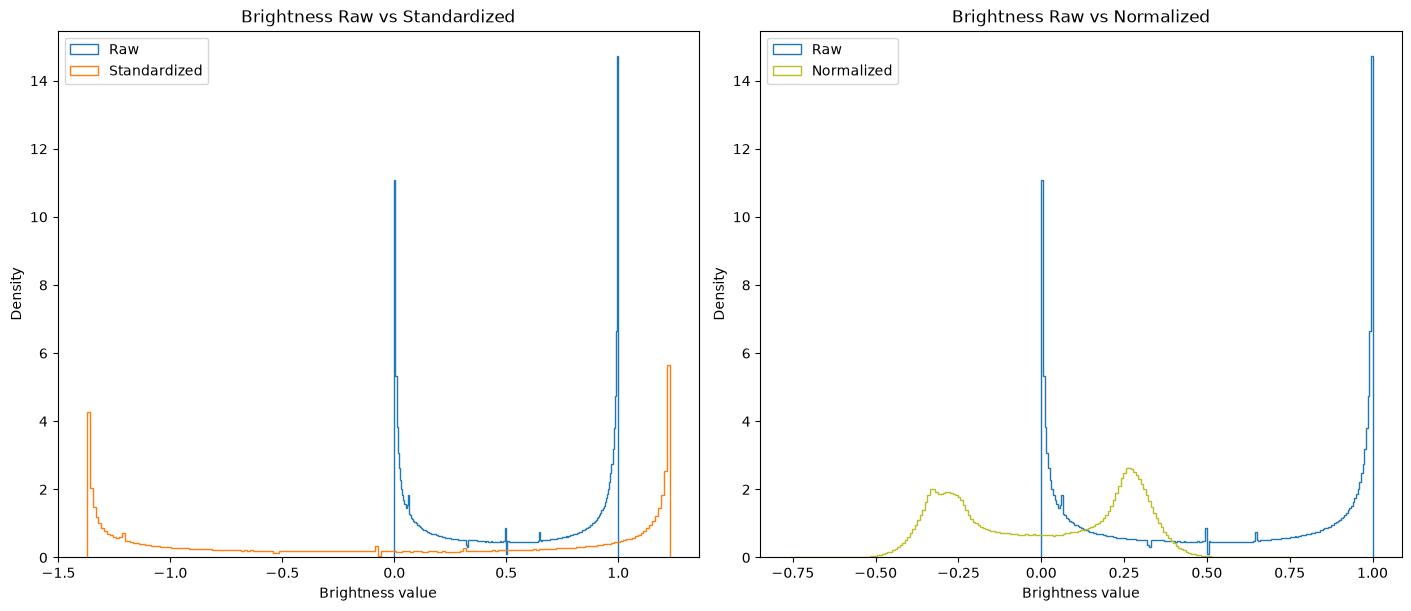

In [55]:
brightness_col = np.flatnonzero(feature_names == "brightness")[0]
brightness_raw = features_raw[:, brightness_col]
brightness_scaled = features_scaled[:, brightness_col]
brightness_normalized = features_norm[:, brightness_col]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
comparisons = [
    ("Standardized", brightness_scaled, "tab:orange"),
    ("Normalized", brightness_normalized, "tab:olive"),
]
for axis, (label, values, color) in zip(axes, comparisons):
    axis.hist(brightness_raw, bins=200, density=True, histtype="step", color="tab:blue", label="Raw")
    axis.hist(values, bins=200, density=True, histtype="step", color=color, label=label)
    axis.set(title=f"Brightness Raw vs {label}", xlabel="Brightness value", ylabel="Density")
    axis.legend()
plt.show()

In [56]:
brightness_stats_df = pd.DataFrame(
    [
        (values.min(), values.max(), values.mean(), np.median(values), values.std())
        for values in (brightness_raw, brightness_scaled, brightness_normalized)
    ],
    index=["raw", "standardized", "normalized"],
    columns=["min", "max", "mean", "median", "std"],
)

display(Markdown("**Basic stats for brightness**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(brightness_stats_df)

brightness_raw_shares = pd.Series({
    "Below 0.01": (brightness_raw < 0.01).mean(),
    "Below 0.10": (brightness_raw < 0.10).mean(),
    "At or above 0.50": (brightness_raw >= 0.50).mean(),
    "Above 0.90": (brightness_raw > 0.90).mean(),
    "Above 0.99": (brightness_raw > 0.99).mean(),
}, name="Share of recordings")
display(brightness_raw_shares.to_frame().style.format("{:.2%}"))

**Basic stats for brightness**

,min,max,mean,median,std
raw,0.00000,1.00000,0.52761,0.56510,0.38408
standardized,-1.37370,1.22992,0.00000,0.09761,1.00000
normalized,-0.75986,0.75382,0.00371,0.02651,0.26254


,Share of recordings
Below 0.01,8.21%
Below 0.10,24.05%
At or above 0.50,53.21%
Above 0.90,29.11%
Above 0.99,10.69%


In [57]:
brightness_tracks = Track.objects.select_related("album").prefetch_related("artists").in_bulk(brightness_mbids)
brightness_rows = []
for mbid, label in brightness_examples.items():
    track = brightness_tracks.get(mbid)
    mbid_bytes = np.void(uuid.UUID(mbid).bytes)
    indices = np.flatnonzero(matrix_mbids == mbid_bytes)
    if track is None or indices.size == 0:
        print(f"Recording {mbid} is missing from the database or feature matrix.")
        continue
    index = indices[0]
    brightness_rows.append({
        "expected timbre": label,
        "title": track.title,
        "artists": ", ".join(artist.name for artist in track.artists.all()),
        "album": track.album.name if track.album else None,
        "submissions": track.submissions,
        "raw": brightness_raw[index],
        "standardized": brightness_scaled[index],
        "normalized": brightness_normalized[index],
    })

brightness_df = pd.DataFrame(brightness_rows)
display(Markdown("**Merged brightness scores for selected recordings**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(brightness_df)

**Merged brightness scores for selected recordings**

,expected timbre,title,artists,album,submissions,raw,standardized,normalized
0,Bright,Take On Me,a-ha,Hunting High and Low,377,0.99218,1.20956,0.28614
1,Softer than studio,Take On Me (MTV Unplugged - Summer Solstice),a-ha,Deadpool 2 (Original Motion Picture Soundtrack),135,0.48692,-0.10594,-0.02258
2,Bright,Walking on Sunshine,Katrina and the Waves,Katrina & The Waves,259,0.99449,1.21557,0.30016
3,Bright,Popcorn,Hot Butter,Popcorn,116,0.99254,1.21050,0.29838
4,Bright,Blackbird,The Beatles,The Beatles,291,0.99575,1.21886,0.24855
5,Bright,Territorial Pissings,Nirvana,Nevermind,226,0.16572,-0.94222,-0.16535
6,Dark,Blue in Green,Miles Davis,Lincoln Center NY 1964,233,0.04265,-1.26266,-0.39199
7,Dark,On the Nature of Daylight,Max Richter,The Blue Notebooks,37,0.03583,-1.28041,-0.36274
8,Dark,Boadicea,Enya,The Celts,178,0.00144,-1.36996,-0.28033
9,Dark,Mad World,Gary Jules,Trading Snakeoil for Wolftickets,29,0.97170,1.15625,0.40677


In [58]:
# Keep the source table in the same order as the selected examples.
brightness_stats_by_mbid = {mbid: feature_stats.get(mbid, {}) for mbid in brightness_mbids}
brightness_submission_stats = export_stats(brightness_stats_by_mbid, feature="timbre")
brightness_submission_stats.insert(0, "expected timbre", list(brightness_examples.values()))

display(Markdown("**Brightness predictions from source submissions**"))
with pd.option_context("display.float_format", "{:,.5f}".format):
    display(brightness_submission_stats[[
        "expected timbre", "title", "artists", "total_pred", "bright_count", "dark_count",
        "all_bright_median", "all_bright_std",
    ]])

**Brightness predictions from source submissions**

,expected timbre,title,artists,total_pred,bright_count,dark_count,all_bright_median,all_bright_std
0,Bright,Take On Me,a-ha,384,383,1,0.99218,0.05953
1,Softer than studio,Take On Me (MTV Unplugged - Summer Solstice),a-ha,135,2,133,0.48692,0.04013
2,Bright,Walking on Sunshine,Katrina and the Waves,261,258,3,0.99449,0.07933
3,Bright,Popcorn,Hot Butter,116,115,1,0.99254,0.09960
4,Bright,Blackbird,The Beatles,294,286,8,0.99583,0.14701
5,Bright,Territorial Pissings,Nirvana,226,0,226,0.16572,0.08306
6,Dark,Blue in Green,Miles Davis,234,4,230,0.04267,0.08493
7,Dark,On the Nature of Daylight,Max Richter,37,0,37,0.03583,0.01444
8,Dark,Boadicea,Enya,178,0,178,0.00144,0.01597
9,Dark,Mad World,Gary Jules,30,28,2,0.97280,0.18623


##### Conclusions

The median raw brightness score was $0.565$. Scores clustered near both ends, with $24.05\%$ below $0.10$ and $29.11\%$ above $0.90$. Vector normalization reduced the standard deviation from $1.000$ after standardization to $0.263$.

The studio version of a-ha's *Take On Me* scored $0.992$, compared with $0.487$ for the unplugged version. The bright class won $383$ of $384$ source predictions for the studio version, while the dark class won $133$ of $135$ for the unplugged version. The Beatles' acoustic *Blackbird* scored $0.996$, and Enya's synth-driven *Boadicea* scored $0.001$.

Two examples went against the listening labels. All $226$ predictions for Nirvana's *Territorial Pissings* favored dark, while $28$ of $30$ predictions for Gary Jules's *Mad World* favored bright. Every merged score was within $0.002$ of its source median in this set, so the mismatches were already present in the source predictions.

#### MIREX moods

[AcousticBrainz cluster definitions](https://acousticbrainz.org/datasets/accuracy#moods_mirex)

In [59]:
mirex_labels = (
    "(1) Rousing",
    "(2) Cheerful",
    "(3) Bittersweet",
    "(4) Humorous",
    "(5) Intense",
)
mirex_columns = [f"moods_mirex_{cluster}" for cluster in range(1, len(mirex_labels) + 1)]
mirex_values = feature_df[mirex_columns].to_numpy()

mirex_maxima = mirex_values == mirex_values.max(axis=1, keepdims=True)
mirex_unique_winner = mirex_maxima.sum(axis=1) == 1

print(f"Valid rows with a tied highest score: {(~mirex_unique_winner).sum():,}")

mirex_summary = pd.DataFrame(
    {
        "Mean score": mirex_values.mean(axis=0),
        "Share of unique winners": mirex_maxima[mirex_unique_winner].mean(axis=0),
    },
    index=mirex_labels,
)
display(mirex_summary.style.format("{:.2%}"))

Valid rows with a tied highest score: 0


,Mean score,Share of unique winners
(1) Rousing,10.82%,1.55%
(2) Cheerful,16.62%,15.40%
(3) Bittersweet,25.45%,27.70%
(4) Humorous,13.95%,5.09%
(5) Intense,33.15%,50.27%


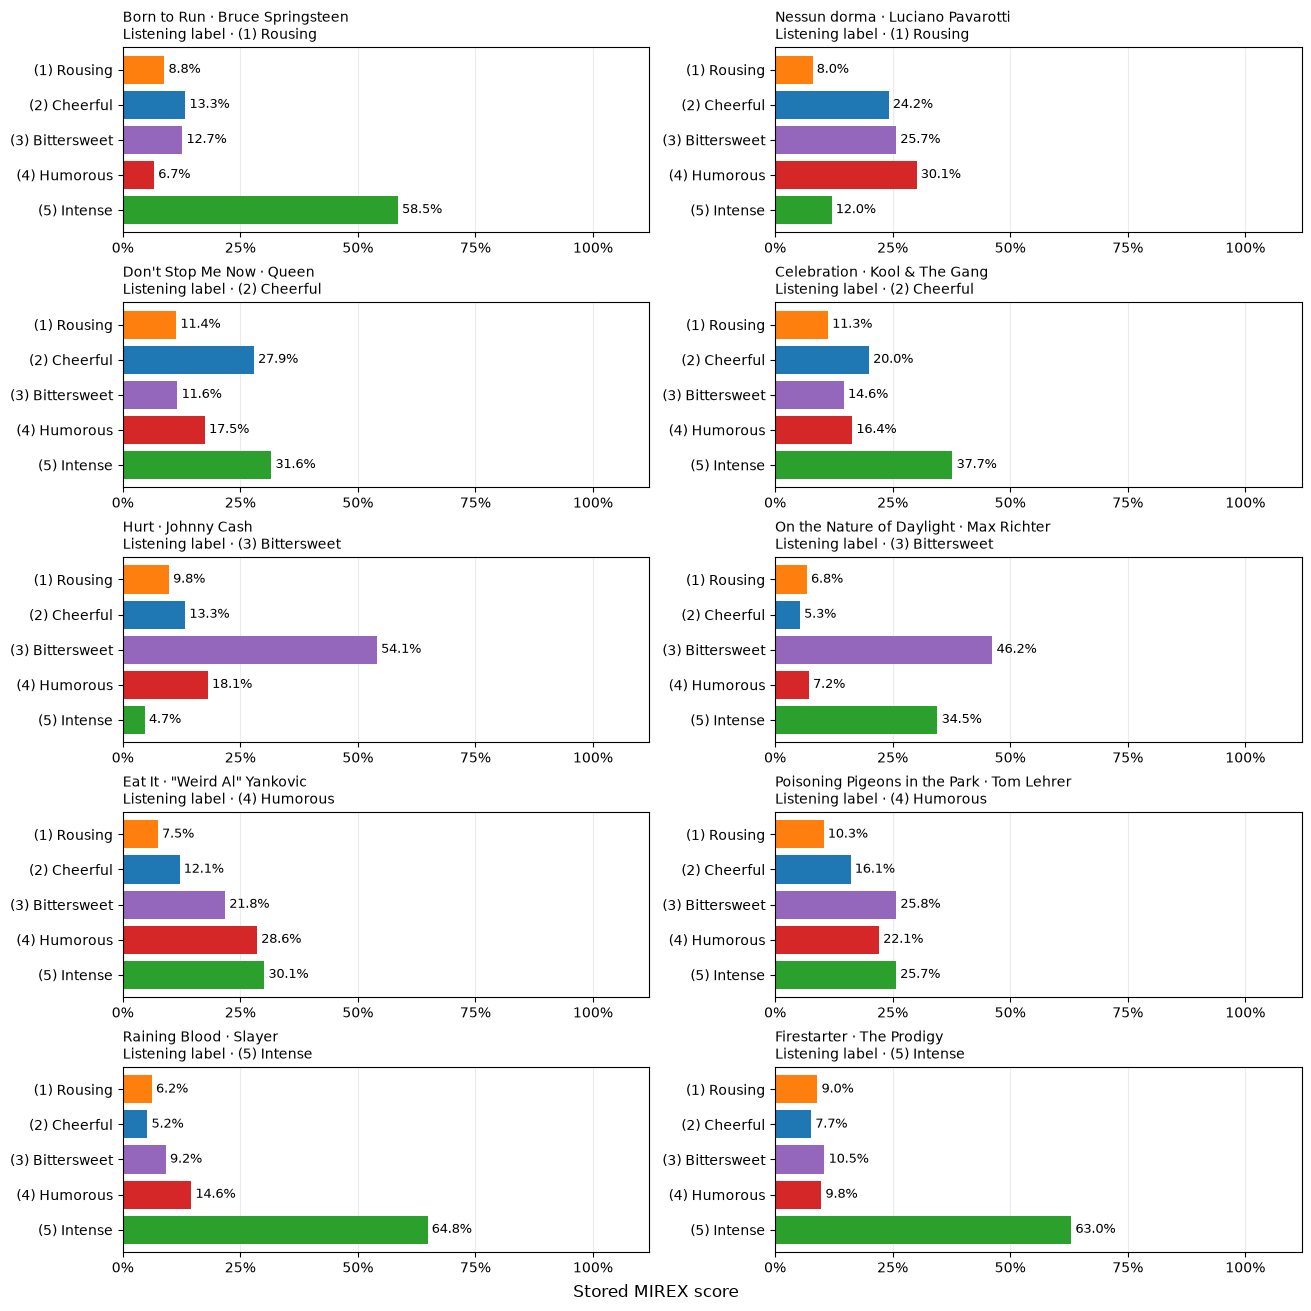

In [60]:
# Map each recording MBID to its expected cluster from listening.
mirex_examples = {
    "7ada2178-c1db-4a24-9760-810681e95308": 1,  # Born to Run - Bruce Springsteen
    "5f4b70fb-2fc0-421c-b4eb-dc8576e15e37": 1,  # Nessun dorma - Luciano Pavarotti
    "d4009c09-a339-4b89-bc45-d91ab649acb6": 2,  # Don't Stop Me Now - Queen
    "7d9d4262-656c-4e93-ad42-0e0ccfbf0635": 2,  # Celebration - Kool & the Gang
    "25d8de5e-3662-4ffd-8dea-511a696ac3e7": 3,  # Hurt - Johnny Cash
    "b75c56c6-cbfc-4d1a-83fd-b2e3f97194cf": 3,  # On the Nature of Daylight - Max Richter
    "4f311aad-865f-4b36-a6bb-e38926bafdb9": 4,  # Eat It - “Weird Al” Yankovic
    "c3a3b381-9f44-45be-b16e-49534277f26b": 4,  # Poisoning Pigeons in the Park - Tom Lehrer
    "1675aafe-397d-41fc-b7f6-fde5681f56c4": 5,  # Raining Blood - Slayer
    "3dabfc40-33b4-4dba-8d94-79e77c4d1448": 5,  # Firestarter - The Prodigy
}

mirex_tracks = Track.objects.prefetch_related("artists").in_bulk(mirex_examples)
mirex_matrix_mbids = feature_store["mbids"]
mirex_recording_scores = {}
mirex_colors = ("tab:orange", "tab:blue", "tab:purple", "tab:red", "tab:green")
fig, axes = plt.subplots(5, 2, figsize=(13, 13), layout="constrained")
for axis, (mbid, expected_cluster) in zip(axes.flat, mirex_examples.items()):
    track = mirex_tracks.get(mbid)
    title = track.title if track else mbid
    artists = ", ".join(artist.name for artist in track.artists.all()) if track else ""
    heading = f"{title} · {artists}" if artists else title
    axis.set_title(
        f"{heading}\nListening label · {mirex_labels[expected_cluster - 1]}",
        loc="left",
        fontsize=10,
    )
    indices = np.flatnonzero(mirex_matrix_mbids == np.void(uuid.UUID(mbid).bytes))

    scores = mirex_values[indices[0]]
    mirex_recording_scores[mbid] = scores
    bars = axis.barh(mirex_labels, scores, color=mirex_colors)
    axis.bar_label(bars, labels=[f"{score:.1%}" for score in scores], padding=3, fontsize=9)
    axis.invert_yaxis()
    axis.set(xticks=[0, 0.25, 0.50, 0.75, 1], xlim=(0, 1.12))
    axis.xaxis.set_major_formatter("{x:.0%}")
    axis.set_axisbelow(True)
    axis.grid(axis="x", alpha=0.25)

fig.supxlabel("Stored MIREX score")
plt.show()

The submission cache includes source records that the production ingest may skip. The table compares the stored scores with the average of available valid source predictions.

In [61]:
from ingest.core.track_processing_helpers import MIREX_ORDER, extract_prob_vector

mirex_submissions = analysis_helpers.get_tracks_submissions(list(mirex_recording_scores))
if mirex_submissions is None:
    print("The source submission cache is unavailable.")
else:
    mirex_source_rows = []
    for mbid, stored in mirex_recording_scores.items():
        track = mirex_tracks.get(mbid)
        source_scores = np.array([
            extract_prob_vector(submission.get("highlevel"), "moods_mirex", MIREX_ORDER)
            for submission in mirex_submissions[mbid]
        ]).reshape(-1, len(MIREX_ORDER))
        valid_source = (
            ((source_scores >= 0) & (source_scores <= 1)).all(axis=1)
            & np.isclose(source_scores.sum(axis=1), 1.0)
        )
        max_difference = np.nan
        if valid_source.any():
            average = source_scores[valid_source].mean(axis=0)
            max_difference = np.abs(stored - average).max()
        mirex_source_rows.append({
            "Recording": track.title if track else mbid,
            "Valid source predictions": valid_source.sum(),
            "Stored leader": mirex_labels[stored.argmax()],
            "Max score difference vs. source average": max_difference,
        })

    mirex_source_comparison = pd.DataFrame(mirex_source_rows)
    display(mirex_source_comparison.style.hide(axis="index").format({
        "Max score difference vs. source average": "{:.2%}",
    }, na_rep="—"))

Trying to get submissions from cache.


Recording,Valid source predictions,Stored leader,Max score difference vs. source average
Born to Run,294,(5) Intense,0.01%
Nessun dorma,9,(4) Humorous,0.00%
Don't Stop Me Now,287,(5) Intense,0.08%
Celebration,141,(5) Intense,0.00%
Hurt,251,(3) Bittersweet,0.03%
On the Nature of Daylight,37,(3) Bittersweet,0.00%
Eat It,87,(5) Intense,0.00%
Poisoning Pigeons in the Park,28,(3) Bittersweet,0.00%
Raining Blood,47,(5) Intense,0.00%
Firestarter,153,(5) Intense,0.00%


##### Conclusions

*"Intense"* was the highest-scoring cluster for 50.27% of recordings, and *"Rousing"* led for 1.55%.

The leading cluster matched the listening label in four of the ten examples. Both *"Bittersweet"* examples matched, as did the two *"Intense"* examples. *"Intense"* also led for both *"Cheerful"* examples. *"Humor"* scored 28.6% for *“Eat It,”* just behind *"Intense"* at 30.1%.

Across these ten recordings, each stored score was within 0.08 percentage points of the average from valid cached submissions. So the aggregate numbers in the feature matrix are very close to the consensus in the dataset archives.

TL;DR Mixed results

### Missing Data

#### Missing Release Year

In [62]:
years: npt.NDArray[np.int16] = np.array(feature_store["years"])
num_tracks = len(years)
zero_years = np.sum(years == 0)

print(f"Tracks missing a release year: {fg.MAGENTA}{zero_years:,}{fg.RESET} / {fg.GREEN}{num_tracks:,}{fg.RESET}")

mbids_raw: npt.NDArray[np.void] = feature_store["mbids"]
zero_year_mbids_raw = random.sample(mbids_raw[years == 0].tolist(), 10)
zero_year_mbids = [str(uuid.UUID(bytes=mbid)) for mbid in zero_year_mbids_raw]

zero_year_tracks_qs = (
    Track.objects.filter(musicbrainz_recordingid__in=zero_year_mbids)
    .select_related("album")
    .prefetch_related("artists")
)

zero_year_tracks_df = pd.DataFrame(
    [
        (
            track.title,
            ", ".join(artist.name for artist in track.artists.all()),
            track.album.name if track.album else "<no album>",
            track.album.date if track.album else None,
            track.musicbrainz_recordingid,
        )
        for track in zero_year_tracks_qs
    ],
    columns=["title", "artists", "album", "album_date", "mbid"],
)

display(Markdown("**Sample of tracks missing a release year**"))
display(zero_year_tracks_df)

Tracks missing a release year: 250,540 / 5,261,105


**Sample of tracks missing a release year**

,title,artists,album,album_date,mbid
0,Jack Of Spades Vs. Let's Dance,Boogie Down Productions,<no album>,None,0059e415-2b81-3c77-86f5-e52c7c9226bb
1,Pull the Wool,Michelle Young,Marked for Madness,None,1a269fc9-be88-4a51-844b-8575f7179542
2,Zapatos Rojos,Les Luthiers,Gerardo Masana Y La Fundación De LES Luthiers,None,1c271f10-e961-4288-9313-74c4ce66aefe
3,Unit 8: Lesson 1,[unknown],New Live 5e : CD audio pour l'élève,None,693be651-6868-4ec8-9c40-3bcd4235f9d3
4,Jitterbuggin' Baby,Houserockers,Lets Whip Up a Tornado,None,88c0379e-35f4-4d93-8498-27fb16011a21
5,We Can Do It (a) :60,Andy Clark,You Are Here 3,None,9d801cfe-6b69-4b27-af67-30210db7d6ba
6,Bedtime Stories,James Clarke,The Choir,None,c6378d95-30ca-4960-9d92-387073c90d64
7,15-8,The Adams,V2.05,None,c9334824-9f3e-4671-91b6-38b28768426d
8,Smart Bomb,Sweet-tex,Clubcutz,None,d0d76184-078d-4fcb-997b-e66516e419b1
9,Shifting Sands,Bob Foster,Shades of Green,None,ed7d24f1-6d49-4b87-b343-be6b7546db91


Due to the way we're ingesting data, there's a chance that a song might be included without a release year if it's JSON metadata didn't contain a year for the album. This is another indicator that we should only be pulling in audio features from the AB dataset and use MusicBrainz for the metadata.

In [63]:
recording_mbids = [
    "b0054557-397c-49ff-884d-085522b851bc",
]
tracks_by_mbid = (
    Track.objects.select_related("album")
    .prefetch_related("artists")
    .in_bulk(recording_mbids)
)

recording_mbid_bytes = [uuid.UUID(mbid).bytes for mbid in recording_mbids]
matrix_mbids = feature_store["mbids"]
matrix_matches = np.isin(matrix_mbids, np.array(recording_mbid_bytes, dtype="V16"))
years_by_mbid = {
    mbid.tobytes(): int(year)
    for mbid, year in zip(matrix_mbids[matrix_matches], feature_store["years"][matrix_matches])
}

recording_rows = []
for mbid, mbid_bytes in zip(recording_mbids, recording_mbid_bytes):
    recording = tracks_by_mbid.get(mbid)
    album = recording.album if recording else None
    recording_rows.append((
        mbid,
        recording.title if recording else None,
        ", ".join(artist.name for artist in recording.artists.all()) if recording else None,
        recording.submissions if recording else None,
        album.name if album else None,
        album.date if album else None,
        years_by_mbid.get(mbid_bytes),
    ))

recording_details = pd.DataFrame(
    recording_rows,
    columns=["mbid", "title", "artists", "submissions", "album", "db_album_date", "feature_matrix_year"],
).astype({"submissions": "Int64", "feature_matrix_year": "Int64"})
display(recording_details.style.hide(axis="index").format(na_rep=""))

mbid,title,artists,submissions,album,db_album_date,feature_matrix_year
b0054557-397c-49ff-884d-085522b851bc,Squeaky Clean (30 second version),Henning Lohner,2,Comedy,2002-01-01,0
